In [1]:
# 1. Setup and project paths
from pathlib import Path
import os

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Project root: notebook is stored in dashboard_notebooks/
PROJECT_ROOT = Path.cwd().parent
os.chdir(PROJECT_ROOT)

# Main project directories
RAW_DIR = PROJECT_ROOT / "raw_data"
PROCESSED_DIR = PROJECT_ROOT / "processing_data"
HYDRO_DIR = RAW_DIR / "hydrology"
OUTPUT_DIR = PROCESSED_DIR / "upstream_rainfall_outputs"

print("Project root:", PROJECT_ROOT)
print("Raw data exists:", RAW_DIR.exists())
print("Processing data exists:", PROCESSED_DIR.exists())
print("Hydrology data exists:", HYDRO_DIR.exists())


Project root: c:\Users\20242408\OneDrive - TU Eindhoven\Documenten\DATA SCIENCE BACHELOR\Jaar 3\Q1\Capstone data challenge\JBG060_ZHL_2026
Raw data exists: True
Processing data exists: True
Hydrology data exists: True


In [2]:
# 2. Inspect available course data loaders
LOADING_FILE = PROCESSED_DIR / "loading.py"

with LOADING_FILE.open("r", encoding="utf-8") as f:
    loader_source = f.read()

for i, line in enumerate(loader_source.splitlines(), start=1):
    if line.startswith(("def ", "class ", "import ", "from ")):
        print(f"{i:4}: {line}")

   1: import pandas as pd
   2: import xarray as xr
   3: import io
   4: import numpy as np
   5: from pathlib import Path
   6: from tqdm import tqdm
  11: def load_dartmouth_data() -> dict[int, pd.DataFrame]:
  46: def load_lake_stations() -> dict[int, pd.DataFrame]:
 121: def load_rainfall_runoff(years: np.ndarray) -> xr.Dataset:
 166: def process_ET(year:int, target_longitude: float = 30.725, target_latitude: float = 9.475) -> None:
 234: def load_processed_ET(years: np.ndarray, target_longitude: float, target_latitude:  float) -> dict[int, pd.DataFrame]:
 257: def load_flood_masks(years: np.array, bbox: dict = None) -> pd.DataFrame:
 332: def flood_mask_bbox(df: pd.DataFrame, bbox: dict) -> pd.DataFrame:
 352: def main():


In [3]:
# 3. Inspect relevant loader functions

lines = loader_source.splitlines()

for start, end in [(11, 45), (121, 165), (257, 331)]:
    print(f"\n{'=' * 20} Lines {start}-{end} {'=' * 20}")
    print("\n".join(
        f"{i + 1:4}: {lines[i]}"
        for i in range(start - 1, min(end, len(lines)))
    ))


==================== Lines 11-45 ====================
  11: def load_dartmouth_data() -> dict[int, pd.DataFrame]:
  12:     """
  13:     Returns a dictionary with for each station, referenced by the area id, the discharge over time.
  14: 
  15:     Also, this function loads the information Excel file, which provides for each station:
  16:     - area id
  17:     - station number
  18:     - country
  19:     - latitude
  20:     - longitude   
  21: 
  22:     This data is downloaded from: https://floodobservatory.colorado.edu
  23:     """
  24:     base_path: str = './raw_data/Darthmouth Flood Observatory'
  25:     data_info = pd.read_excel(base_path + '/information.xlsx')
  26: 
  27:     print("Information regarding each station:")
  28:     print(data_info.head())
  29: 
  30:     area_ids = data_info['area id'].values
  31: 
  32:     # Create a dictionary with all stations data
  33:     data = {}
  34:     for area_id in area_ids:
  35:         df = pd.read_csv(f'{base_pat

In [4]:
# 4. Check source-data availability without loading datasets

rain_dir = RAW_DIR / "rainfall and runoff"
flood_dir = RAW_DIR / "flood_masks"
dfo_dir = RAW_DIR / "Darthmouth Flood Observatory"

print("ERA5 yearly files:")
era5_files = sorted(rain_dir.glob("ERA5_*.nc"))
print(f"Found {len(era5_files)} files")
print("First files:", [p.name for p in era5_files[:5]])
print("Last files:", [p.name for p in era5_files[-5:]])

print("\nFlood-mask folders:")
for subdir in ["compact_recurring", "compact_unusual"]:
    folder = flood_dir / subdir
    files = sorted(folder.glob("*.parquet")) if folder.exists() else []
    print(f"{subdir}: {len(files)} files")
    print("  Examples:", [p.name for p in files[:3]])

print("\nDartmouth files:")
if dfo_dir.exists():
    for p in sorted(dfo_dir.iterdir())[:10]:
        print(" ", p.name)
else:
    print("Folder not found")


ERA5 yearly files:
Found 26 files
First files: ['ERA5_2000.nc', 'ERA5_2001.nc', 'ERA5_2002.nc', 'ERA5_2003.nc', 'ERA5_2004.nc']
Last files: ['ERA5_2021.nc', 'ERA5_2022.nc', 'ERA5_2023.nc', 'ERA5_2024.nc', 'ERA5_2025.nc']

Flood-mask folders:
compact_recurring: 52 files
  Examples: ['flood_events_h20v08_2000.parquet', 'flood_events_h20v08_2001.parquet', 'flood_events_h20v08_2002.parquet']
compact_unusual: 52 files
  Examples: ['flood_events_h20v08_2000.parquet', 'flood_events_h20v08_2001.parquet', 'flood_events_h20v08_2002.parquet']

Dartmouth files:
  100205_discharge.csv
  11808_discharge.csv
  11842_discharge.csv
  1505_discharge.csv
  1541_discharge.csv
  1542_discharge.csv
  1543_discharge.csv
  1544_discharge.csv
  1545_discharge.csv
  1547_discharge.csv


In [5]:
# 5. Check test-year inputs and Dartmouth station metadata

TEST_YEAR = 2020
TILES = ["h20v08", "h21v08"]

print(f"Flood-mask files for {TEST_YEAR}:")
for category in ["compact_recurring", "compact_unusual"]:
    for tile in TILES:
        path = flood_dir / category / f"flood_events_{tile}_{TEST_YEAR}.parquet"
        print(f"{category:18} {tile}: {'FOUND' if path.exists() else 'MISSING'}")

info_path = dfo_dir / "information.xlsx"
print("\nDartmouth metadata exists:", info_path.exists())

if info_path.exists():
    dfo_info = pd.read_excel(info_path)
    print("Metadata shape:", dfo_info.shape)
    print("Columns:", dfo_info.columns.tolist())
    print(dfo_info.head(10).to_string(index=False))


Flood-mask files for 2020:
compact_recurring  h20v08: FOUND
compact_recurring  h21v08: FOUND
compact_unusual    h20v08: FOUND
compact_unusual    h21v08: FOUND

Dartmouth metadata exists: True
Metadata shape: (13, 5)
Columns: ['station nr', 'area id', 'Country', 'latitude', 'longitude']
 station nr  area id     Country  latitude  longitude
        334   100205 South Sudan       9.6       31.6
        224     1541       Sudan      12.4       32.8
        225     1542       Sudan      13.9       32.4
        226     1543       Sudan      14.9       32.2
        227     1544       Sudan      13.1       33.9
        228     1545       Sudan      13.8       33.6
        229     1547       Sudan      15.6       32.4
        230     1548       Sudan      16.6       32.9
        289    11808       Sudan      18.8       32.0
        290    11842       Sudan      21.5       31.0


In [6]:
# 6. Inspect study-area boundaries and hydrology inputs

ADMIN_DIR = RAW_DIR / "Administrative boundaries"

admin_files = list(ADMIN_DIR.glob("*.geojson"))
print("Administrative GeoJSON files:")
for p in admin_files:
    print(" ", p.name)

admin2_path = ADMIN_DIR / "ssd_admin2.geojson"

if admin2_path.exists():
    admin2 = gpd.read_file(admin2_path)
    print("\nAdmin-2 boundary shape:", admin2.shape)
    print("CRS:", admin2.crs)
    print("Columns:", admin2.columns.tolist())

    name_cols = [
        c for c in admin2.columns
        if any(word in c.lower() for word in ["name", "adm2", "admin"])
    ]
    print("\nPossible name columns:", name_cols)

    for col in name_cols:
        print(f"\nValues in {col}:")
        print(
            admin2.loc[
                admin2[col].astype(str).str.contains(
                    "Ayod|Bor|Malakal", case=False, na=False
                ),
                [col]
            ].drop_duplicates().to_string(index=False)
        )

print("\nHydroBASINS levels:")
for level in range(1, 13):
    path = HYDRO_DIR / "hydrobasins_africa" / f"hybas_af_lev{level:02d}_v1c.shp"
    print(f"Level {level:02d}: {'FOUND' if path.exists() else 'MISSING'}")

print("\nHydroRIVERS:")
river_files = list(HYDRO_DIR.rglob("HydroRIVERS_v10_af.shp"))
for p in river_files:
    print(" ", p.relative_to(PROJECT_ROOT))


Administrative GeoJSON files:
  ssd_admin0.geojson
  ssd_admin1.geojson
  ssd_admin2.geojson
  ssd_admin3.geojson
  ssd_adminlines.geojson
  ssd_adminpoints.geojson

Admin-2 boundary shape: (79, 27)
CRS: EPSG:4326
Columns: ['adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'adm2_ref_name', 'center_lat', 'center_lon', 'geometry']

Possible name columns: ['adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm2_ref_name']

Values in adm2_name:
adm2_name
     Ayod
Bor South
    Pibor
  Malakal

Values in adm2_name1:
Empty DataFrame
Columns: [adm2_name1]
Index: []

Values in adm2_name2:
Empty DataFrame
Columns: [adm2_name2]
Inde

Study areas found: 3
adm2_name  adm1_name    area_sqkm  center_lat  center_lon
     Ayod    Jonglei 13449.146531    8.270447   31.004533
Bor South    Jonglei 13962.835622    6.488630   31.918488
  Malakal Upper Nile   754.680410    9.666420   31.729675


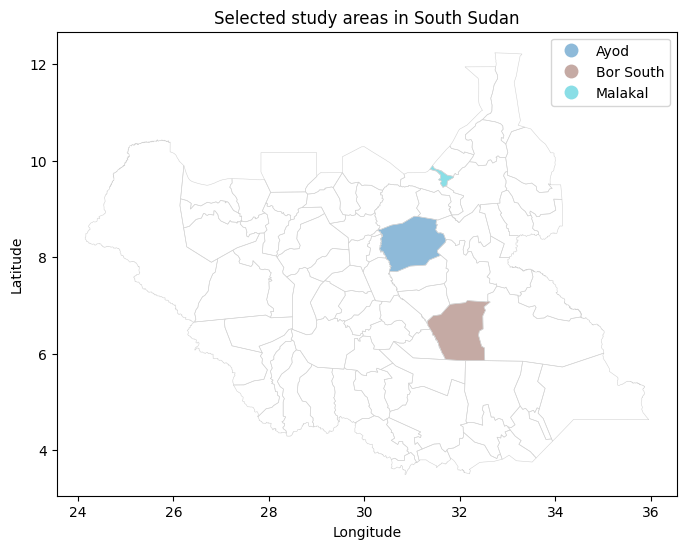

In [7]:
# 7. Define the study areas

STUDY_AREAS = ["Ayod", "Bor South", "Malakal"]

study_areas = admin2.loc[
    admin2["adm2_name"].isin(STUDY_AREAS)
].copy()

study_areas = study_areas.set_index("adm2_name").loc[STUDY_AREAS].reset_index()

print("Study areas found:", len(study_areas))
print(
    study_areas[
        ["adm2_name", "adm1_name", "area_sqkm", "center_lat", "center_lon"]
    ].to_string(index=False)
)

assert len(study_areas) == 3, "One or more study areas were not found."

# Quick visual check
fig, ax = plt.subplots(figsize=(8, 8))
admin2.boundary.plot(ax=ax, linewidth=0.4, color="lightgray")
study_areas.plot(ax=ax, column="adm2_name", legend=True, alpha=0.5)
ax.set_title("Selected study areas in South Sudan")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()


In [8]:
# 8. Inspect HydroBASINS candidates around each study area
HYDROBASINS_DIR = HYDRO_DIR / "hydrobasins_africa"
BASIN_LEVELS = [6, 8, 10]

basin_candidates = {}

for level in BASIN_LEVELS:
    basin_path = HYDROBASINS_DIR / f"hybas_af_lev{level:02d}_v1c.shp"
    basins = gpd.read_file(basin_path)

    # Find basins intersecting each admin-2 study area
    for _, area in study_areas.iterrows():
        area_name = area["adm2_name"]
        intersecting = basins.loc[
            basins.geometry.intersects(area.geometry)
        ].copy()

        basin_candidates[(area_name, level)] = intersecting

        print(
            f"{area_name:10} | Level {level:02d} | "
            f"{len(intersecting)} intersecting basins"
        )

        if not intersecting.empty:
            cols = [
                c for c in [
                    "HYBAS_ID", "NEXT_DOWN", "MAIN_BAS",
                    "SUB_AREA", "UP_AREA", "ORDER"
                ]
                if c in intersecting.columns
            ]
            print(
                intersecting[cols]
                .sort_values("UP_AREA", ascending=False)
                .head(5)
                .to_string(index=False)
            )
        print()


Ayod       | Level 06 | 5 intersecting basins
  HYBAS_ID  NEXT_DOWN   MAIN_BAS  SUB_AREA   UP_AREA  ORDER
1060840450 1060841440 1060034260    1834.9 1162571.6      1
1060837890 1060840450 1060034260   11293.0  552637.4      1
1060841720 1060844660 1060034260   21847.6   21847.6      2
1060846100 1060843040 1060034260   19603.1   19603.7      3
1060844900 1060843030 1060034260    6461.1    6462.0      2

Bor South  | Level 06 | 8 intersecting basins
  HYBAS_ID  NEXT_DOWN   MAIN_BAS  SUB_AREA  UP_AREA  ORDER
1060921740 1060837890 1060034260    9560.6 513204.5      1
1060965920 1060921740 1060034260   14869.1 490384.2      1
1060845900 1060843040 1060034260   19312.6 195178.8      2
1060883500 1060845900 1060034260   20090.9 137130.1      2
1060954680 1060949070 1060034260    5319.2  25856.6      2

Malakal    | Level 06 | 2 intersecting basins
  HYBAS_ID  NEXT_DOWN   MAIN_BAS  SUB_AREA   UP_AREA  ORDER
1060800150 1060798250 1060034260   13960.3 1426241.0      1
1060845900 1060843040 1060

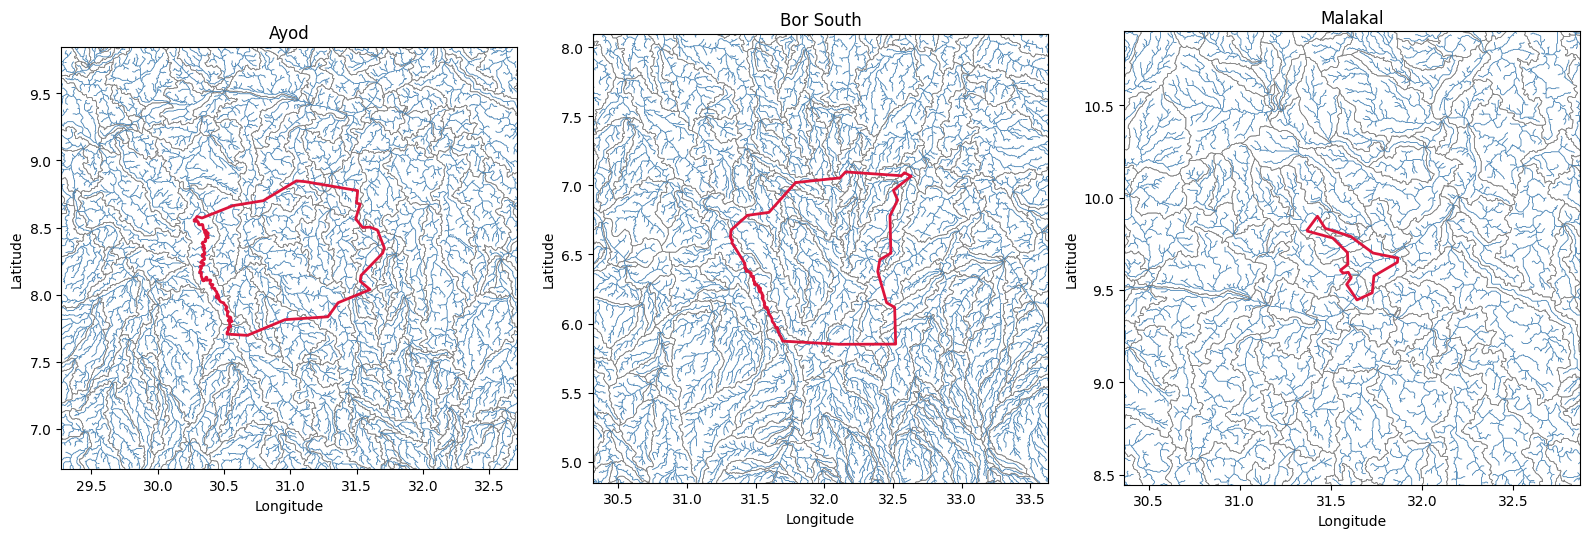

In [9]:
# 9. Map level-8 basin candidates and nearby rivers
BASIN_LEVEL_TO_MAP = 8

basins_l8 = gpd.read_file(
    HYDROBASINS_DIR / f"hybas_af_lev{BASIN_LEVEL_TO_MAP:02d}_v1c.shp"
)

river_path = next(HYDRO_DIR.rglob("HydroRIVERS_v10_af.shp"))
rivers = gpd.read_file(river_path)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for ax, area_name in zip(axes, STUDY_AREAS):
    area = study_areas.loc[
        study_areas["adm2_name"] == area_name
    ]

    # Limit plotting to a local window around the study area
    minx, miny, maxx, maxy = area.total_bounds
    dx, dy = 1.0, 1.0
    bounds = (
        minx - dx, miny - dy,
        maxx + dx, maxy + dy
    )

    local_basins = basins_l8.cx[
        bounds[0]:bounds[2], bounds[1]:bounds[3]
    ]
    local_rivers = rivers.cx[
        bounds[0]:bounds[2], bounds[1]:bounds[3]
    ]

    local_basins.boundary.plot(
        ax=ax, color="gray", linewidth=0.5
    )
    local_rivers.plot(
        ax=ax, color="steelblue", linewidth=0.6
    )
    area.boundary.plot(
        ax=ax, color="crimson", linewidth=2
    )

    ax.set_xlim(bounds[0], bounds[2])
    ax.set_ylim(bounds[1], bounds[3])
    ax.set_title(area_name)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()


In [10]:
# 10. Inspect river segments intersecting each study area

RIVER_ID_COLS = [
    "HYRIV_ID", "NEXT_DOWN", "MAIN_RIV",
    "LENGTH_KM", "UPLAND_SKM", "CATCH_SKM",
    "ORD_STRA", "HYBAS_L12"
]

for _, area in study_areas.iterrows():
    area_name = area["adm2_name"]

    # Select river segments that intersect this administrative polygon
    local_rivers = rivers.loc[
        rivers.geometry.intersects(area.geometry)
    ].copy()

    print(f"\n{'=' * 18} {area_name} {'=' * 18}")
    print("Intersecting river segments:", len(local_rivers))

    cols = [c for c in RIVER_ID_COLS if c in local_rivers.columns]

    # Display the largest upstream areas for inspection, not automatic selection
    print(
        local_rivers[cols]
        .sort_values("UPLAND_SKM", ascending=False)
        .head(10)
        .to_string(index=False)
    )



================== Ayod ==================
Intersecting river segments: 662
 HYRIV_ID  NEXT_DOWN  MAIN_RIV  LENGTH_KM  UPLAND_SKM  CATCH_SKM  ORD_STRA  HYBAS_L12
 10693459   10692951  10047863       1.58    546247.0       2.33         7 1121983150
 10696627   10693459  10047863      13.15    546157.9      67.51         7 1121983150
 10697783   10696627  10047863       5.83    546034.3      20.59         7 1121983750
 10698344   10697783  10047863       1.96    545961.7       3.40         7 1121985190
 10698730   10698344  10047863       1.30    545939.4       3.19         7 1121985190
 10700787   10698730  10047863       7.33    545919.9      27.18         7 1121985190
 10702542   10700787  10047863       5.11    545864.5      19.96         7 1121985190
 10704062   10702542  10047863       4.92    545797.1      17.63         7 1121986530
 10705370   10704062  10047863       4.73    545725.2      12.53         7 1121987600
 10705563   10705370  10047863       0.65    545626.8       0.4

In [11]:
# 11. Trace downstream river connectivity for candidate segments
CANDIDATE_RIVER_IDS = {
    "Ayod": 10693459,
    "Bor South": 10783887,
    "Malakal": 10644623,
}

river_lookup = rivers.set_index("HYRIV_ID", drop=False)
basin_lookup_l8 = basins_l8.set_index("HYBAS_ID", drop=False)

for area_name, start_id in CANDIDATE_RIVER_IDS.items():
    print(f"\n{'=' * 15} {area_name} {'=' * 15}")

    current_id = start_id
    visited = set()
    chain = []

    # Follow NEXT_DOWN until the chain ends or a repeated ID is found
    for _ in range(30):
        if current_id in visited or current_id not in river_lookup.index:
            break

        visited.add(current_id)
        row = river_lookup.loc[current_id]

        # If IDs aren't unique, select the first matching row
        if isinstance(row, pd.DataFrame):
            row = row.iloc[0]

        chain.append({
            "HYRIV_ID": int(row["HYRIV_ID"]),
            "NEXT_DOWN": int(row["NEXT_DOWN"]),
            "UPLAND_SKM": float(row["UPLAND_SKM"]),
            "HYBAS_L12": int(row["HYBAS_L12"]),
        })

        next_id = int(row["NEXT_DOWN"])
        if next_id == 0 or next_id == current_id:
            break
        current_id = next_id

    print(pd.DataFrame(chain).to_string(index=False))

    basin_ids = sorted(set(item["HYBAS_L12"] for item in chain))
    print("Level-12 basin IDs along chain:", basin_ids)



=============== Ayod ===============
 HYRIV_ID  NEXT_DOWN  UPLAND_SKM  HYBAS_L12
 10693459   10692951    546247.0 1121983150
 10692951   10690350    546297.6 1120873890
 10690350   10688847    546381.9 1120873890
 10688847   10688845    546651.0 1120868370
 10688845   10686937    546706.1 1120868370
 10686937   10685667    546734.6 1120868370
 10685667   10683630    546765.8 1120868370
 10683630   10683077    546807.3 1120868370
 10683077   10682727    546857.8 1120868370
 10682727   10681809    548566.0 1120865690
 10681809   10680892    548590.1 1120865690
 10680892   10680139    548669.4 1120865690
 10680139   10679022    549154.9 1120861700
 10679022   10675756    549240.5 1120861700
 10675756   10675411    549385.9 1120858140
 10675411   10671931    549446.1 1120858140
 10671931   10671049    549951.0 1120855470
 10671049   10668815    550032.4 1120855470
 10668815   10666076    550214.7 1120852430
 10666076   10665759    550742.4 1120852020
 10665759   10665402    550788.7 11208

In [12]:
# 12. Inspect HydroBASINS connectivity for the river-chain candidates

basins_l12 = gpd.read_file(
    HYDROBASINS_DIR / "hybas_af_lev12_v1c.shp"
)

basin_ids_by_area = {
    area: sorted({
        int(row["HYBAS_L12"])
        for row in chain
    })
    for area, chain in []  # populated below from river connectivity
}

# Rebuild the river chains and collect their level-12 basin IDs
for area_name, start_id in CANDIDATE_RIVER_IDS.items():
    current_id = start_id
    visited = set()
    ids = []

    for _ in range(100):
        if current_id in visited or current_id not in river_lookup.index:
            break

        visited.add(current_id)
        row = river_lookup.loc[current_id]
        if isinstance(row, pd.DataFrame):
            row = row.iloc[0]

        ids.append(int(row["HYBAS_L12"]))
        next_id = int(row["NEXT_DOWN"])

        if next_id == 0 or next_id == current_id:
            break
        current_id = next_id

    basin_ids_by_area[area_name] = sorted(set(ids))

for area_name, ids in basin_ids_by_area.items():
    selected = basins_l12.loc[basins_l12["HYBAS_ID"].isin(ids)].copy()

    print(f"\n{area_name}: {len(selected)} unique level-12 basins")
    print(
        selected[
            ["HYBAS_ID", "NEXT_DOWN", "SUB_AREA", "UP_AREA"]
        ].sort_values("UP_AREA", ascending=False).to_string(index=False)
    )



Ayod: 38 unique level-12 basins
  HYBAS_ID  NEXT_DOWN  SUB_AREA   UP_AREA
1120798250 1121949260     120.6 1468764.6
1120798400 1120798250      46.3 1468392.9
1120800150 1120798400      18.8 1426241.0
1120803210 1120800150     185.0 1426058.1
1120812230 1120803210     165.8 1425604.3
1120817590 1120812230      86.6 1424901.3
1120819070 1120817590     145.3 1418829.5
1120823490 1120819070     216.5 1418582.6
1120827600 1120823490      36.6 1418171.3
1120828670 1120827600      67.9 1414232.6
1120830780 1120828670     164.5 1414041.5
1121964880 1120830780     208.8 1413876.9
1120833240 1121964880      61.3 1413544.0
1120835180 1120833240     169.0 1412637.5
1121967960 1120835180     191.2 1412468.5
1120843030 1121967960      94.5 1197395.8
1121969540 1120843030     163.3 1197300.6
1120844910 1121969540      15.0 1196811.8
1120844660 1120844910     162.4 1190334.6
1121969010 1120844660     147.8 1190171.6
1121968840 1121969010     185.6 1190023.6
1120841580 1121968840       9.1 1167991.8
1

In [13]:
# 13. Compare basin sizes and spatial overlap with study areas
overlap_rows = []

for level in [8, 10]:
    basins = gpd.read_file(
        HYDROBASINS_DIR / f"hybas_af_lev{level:02d}_v1c.shp"
    )

    for _, area in study_areas.iterrows():
        area_name = area["adm2_name"]
        intersecting = basins.loc[
            basins.geometry.intersects(area.geometry)
        ].copy()

        for _, basin in intersecting.iterrows():
            overlap = basin.geometry.intersection(area.geometry).area
            area_fraction = overlap / area.geometry.area if area.geometry.area else np.nan

            overlap_rows.append({
                "area": area_name,
                "basin_level": level,
                "HYBAS_ID": basin["HYBAS_ID"],
                "NEXT_DOWN": basin["NEXT_DOWN"],
                "SUB_AREA_km2": basin["SUB_AREA"],
                "UP_AREA_km2": basin["UP_AREA"],
                "admin_overlap_fraction": area_fraction,
            })

basin_overlap_summary = pd.DataFrame(overlap_rows)

for area_name in STUDY_AREAS:
    print(f"\n{'=' * 12} {area_name} {'=' * 12}")

    subset = basin_overlap_summary[
        basin_overlap_summary["area"] == area_name
    ]

    for level in [8, 10]:
        level_subset = subset[subset["basin_level"] == level]
        print(
            f"Level {level}: {len(level_subset)} intersecting basins"
        )

        print(
            level_subset.sort_values(
                "admin_overlap_fraction", ascending=False
            ).head(5).to_string(index=False)
        )



============ Ayod ============
Level 8: 29 intersecting basins
area  basin_level   HYBAS_ID  NEXT_DOWN  SUB_AREA_km2  UP_AREA_km2  admin_overlap_fraction
Ayod            8 1080886390 1080876750        3956.6      12150.6                0.195795
Ayod            8 1080874940 1080869140        1413.6       1413.8                0.102941
Ayod            8 1080874930 1080869140        1185.2       1185.5                0.087771
Ayod            8 1080868170 1080852020        1703.7       1704.2                0.086856
Ayod            8 1080876640 1080841720        1054.1       1054.1                0.078097
Level 10: 119 intersecting basins
area  basin_level   HYBAS_ID  NEXT_DOWN  SUB_AREA_km2  UP_AREA_km2  admin_overlap_fraction
Ayod           10 1101988330 1100873890         945.0     545591.3                0.034098
Ayod           10 1100873890 1100868370         792.3     546381.9                0.027533
Ayod           10 1100900030 1100896360         265.7      10213.8                0

In [14]:
# Build a lookup of level-8 basin IDs and their downstream basin IDs.
# NEXT_DOWN = 0 indicates no downstream basin is recorded.

basin_connectivity = basins_l8[
    ["HYBAS_ID", "NEXT_DOWN", "SUB_AREA", "UP_AREA", "geometry"]
].copy()

basin_connectivity["HYBAS_ID"] = basin_connectivity["HYBAS_ID"].astype("int64")
basin_connectivity["NEXT_DOWN"] = basin_connectivity["NEXT_DOWN"].astype("int64")

# Map each basin to the basin immediately downstream of it.
downstream_lookup = basin_connectivity.set_index("HYBAS_ID")["NEXT_DOWN"].to_dict()

# Reverse the links: for each basin, identify the basins that drain directly into it.
upstream_lookup = {}
for basin_id, downstream_id in downstream_lookup.items():
    if downstream_id != 0:
        upstream_lookup.setdefault(downstream_id, []).append(basin_id)

print(f"Level-8 basins loaded: {len(basin_connectivity):,}")
print(f"Basins with a recorded downstream basin: "
      f"{sum(v != 0 for v in downstream_lookup.values()):,}")
print(f"Basins with at least one directly upstream basin: {len(upstream_lookup):,}")


Level-8 basins loaded: 41,372
Basins with a recorded downstream basin: 37,498
Basins with at least one directly upstream basin: 18,564


In [15]:
# Candidate level-8 basins intersecting each study area.
# Area overlap is measured in a projected CRS so the fractions are meaningful.

basins_metric = basins_l8.to_crs("EPSG:6933")
areas_metric = study_areas.to_crs("EPSG:6933")

candidate_rows = []

for _, area in areas_metric.iterrows():
    area_name = area["adm2_name"]
    area_geom = area.geometry

    intersecting = basins_metric.loc[
        basins_metric.geometry.intersects(area_geom)
    ]

    for _, basin in intersecting.iterrows():
        overlap_area = basin.geometry.intersection(area_geom).area
        candidate_rows.append({
            "area": area_name,
            "HYBAS_ID": int(basin["HYBAS_ID"]),
            "NEXT_DOWN": int(basin["NEXT_DOWN"]),
            "SUB_AREA_km2": basin["SUB_AREA"],
            "UP_AREA_km2": basin["UP_AREA"],
            "admin_overlap_fraction": (
                overlap_area / area_geom.area if area_geom.area else np.nan
            ),
            "basin_area": basin.geometry
        })

outlet_candidates = pd.DataFrame(candidate_rows)

for area_name in STUDY_AREAS:
    print(f"\n===== {area_name} =====")
    display(
        outlet_candidates.loc[outlet_candidates["area"] == area_name]
        .drop(columns="basin_area")
        .sort_values("admin_overlap_fraction", ascending=False)
        .head(10)
        .round(3)
    )


===== Ayod =====


,area,HYBAS_ID,NEXT_DOWN,SUB_AREA_km2,UP_AREA_km2,admin_overlap_fraction
19,Ayod,1080886390,1080876750,3956.6,12150.6,0.196
8,Ayod,1080874940,1080869140,1413.6,1413.8,0.103
9,Ayod,1080874930,1080869140,1185.2,1185.5,0.088
21,Ayod,1080868170,1080852020,1703.7,1704.2,0.087
15,Ayod,1080876640,1080841720,1054.1,1054.1,0.078
24,Ayod,1080892610,1080886380,988.9,988.9,0.070
22,Ayod,1080868370,1080852020,2214.6,546857.8,0.062
14,Ayod,1080876750,1080841720,527.9,18659.0,0.039
0,Ayod,1080841720,1080844660,2133.3,21846.5,0.036
23,Ayod,1080892620,1080886380,436.7,4721.7,0.032



===== Bor South =====


,area,HYBAS_ID,NEXT_DOWN,SUB_AREA_km2,UP_AREA_km2,admin_overlap_fraction
53,Bor South,1080947990,1080943000,2372.9,2373.5,0.135
44,Bor South,1080951620,1080950610,2403.2,2403.4,0.127
45,Bor South,1080951720,1080950610,1340.2,1340.3,0.096
50,Bor South,1080940310,1080938020,1553.6,1554.0,0.095
43,Bor South,1080950600,1080942340,870.3,870.3,0.062
40,Bor South,1080942100,1080937440,781.0,781.0,0.054
62,Bor South,1080974850,1080954500,1327.4,10406.7,0.048
61,Bor South,1080974660,1080954500,819.5,819.6,0.043
51,Bor South,1080940020,1080938020,581.8,581.8,0.041
35,Bor South,1080945460,1080934640,471.4,471.4,0.034



===== Malakal =====


,area,HYBAS_ID,NEXT_DOWN,SUB_AREA_km2,UP_AREA_km2,admin_overlap_fraction
63,Malakal,1080828670,1080819070,748.4,1414232.6,0.502
66,Malakal,1080826450,1080823890,399.7,399.7,0.188
65,Malakal,1080835180,1080828670,360.2,1412637.5,0.161
68,Malakal,1080820600,1080826310,532.6,1177.1,0.056
64,Malakal,1080834950,1080828670,845.8,845.8,0.048
67,Malakal,1080826310,1080823890,208.8,1777.7,0.041
69,Malakal,1080843790,1080845900,186.6,186.8,0.005


In [16]:
# Candidate outlets to compare.
# These are diagnostic candidates, not yet validated final outlets.

TEST_OUTLETS = {
    "Ayod": [1080886390, 1080868370, 1080841720],
    "Bor South": [1080947990, 1080951620, 1080974850],
    "Malakal": [1080828670, 1080826450, 1080835180],
}

def trace_upstream(start_basin_id, upstream_lookup):
    """Return the outlet basin and all recursively connected upstream basins."""
    visited = set()
    stack = [int(start_basin_id)]

    while stack:
        basin_id = stack.pop()
        if basin_id in visited:
            continue

        visited.add(basin_id)
        stack.extend(upstream_lookup.get(basin_id, []))

    return visited

trace_rows = []

for area_name, outlet_ids in TEST_OUTLETS.items():
    for outlet_id in outlet_ids:
        connected_ids = trace_upstream(outlet_id, upstream_lookup)
        connected_basins = basin_connectivity.loc[
            basin_connectivity["HYBAS_ID"].isin(connected_ids)
        ]

        trace_rows.append({
            "area": area_name,
            "candidate_outlet": outlet_id,
            "connected_basin_count": len(connected_ids),
            "sum_sub_area_km2": connected_basins["SUB_AREA"].sum(),
            "max_up_area_km2": connected_basins["UP_AREA"].max(),
            "outlet_found_in_data": outlet_id in downstream_lookup
        })

upstream_trace_summary = pd.DataFrame(trace_rows)

display(
    upstream_trace_summary
    .sort_values(["area", "connected_basin_count"], ascending=[True, False])
    .round(1)
)


,area,candidate_outlet,connected_basin_count,sum_sub_area_km2,max_up_area_km2,outlet_found_in_data
1,Ayod,1080868370,862,546844.2,546857.8,True
2,Ayod,1080841720,25,21847.6,21846.5,True
0,Ayod,1080886390,13,12152.1,12150.6,True
5,Bor South,1080974850,15,10407.7,10406.7,True
3,Bor South,1080947990,1,2372.9,2373.5,True
4,Bor South,1080951620,1,2403.2,2403.4,True
6,Malakal,1080828670,1948,1421934.0,1414232.6,True
8,Malakal,1080835180,1946,1420339.8,1412637.5,True
7,Malakal,1080826450,1,399.7,399.7,True


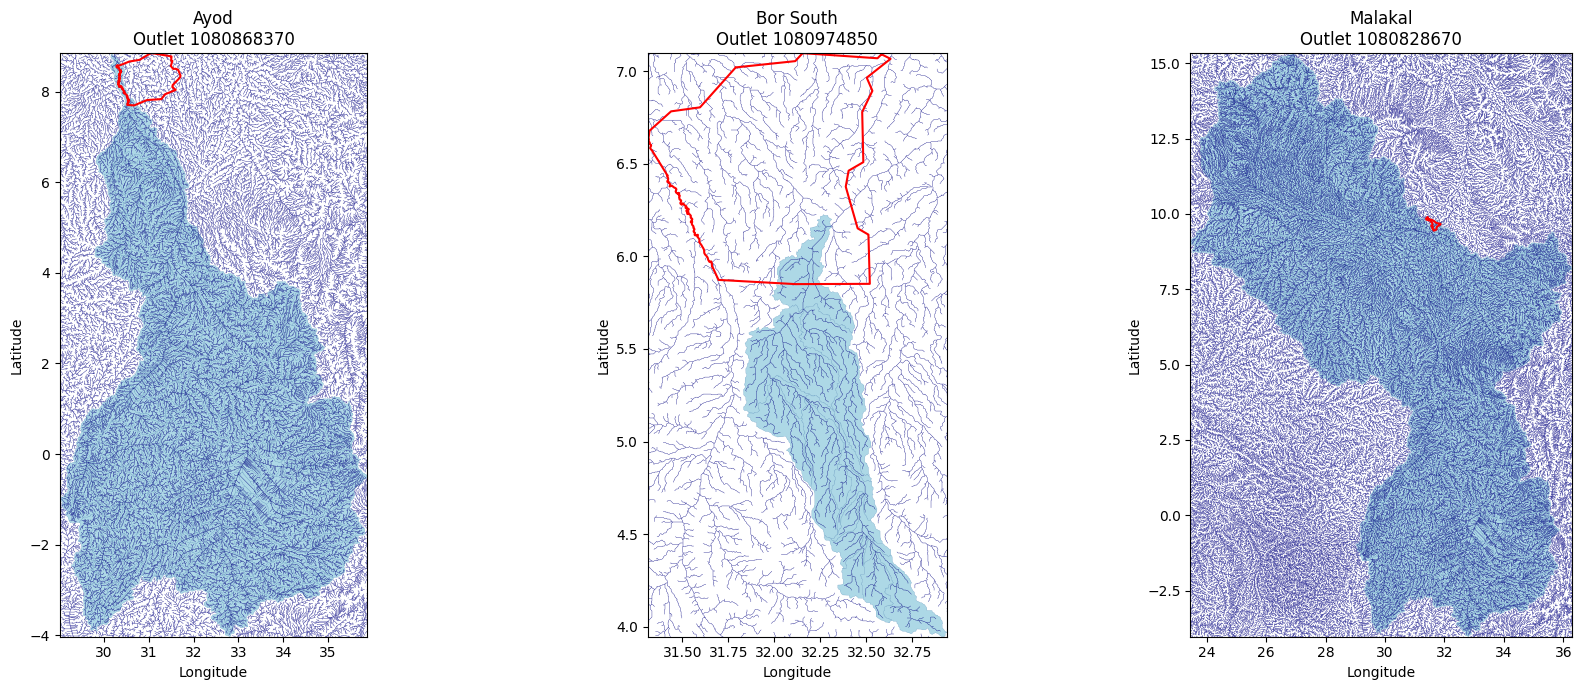

In [17]:
# Map the candidate connected basin networks.
# These are diagnostic maps, not final catchment delineations.

MAP_OUTLETS = {
    "Ayod": 1080868370,
    "Bor South": 1080974850,
    "Malakal": 1080828670,
}

basins_map = basin_connectivity.to_crs("EPSG:4326")
study_areas_map = study_areas.to_crs("EPSG:4326")
rivers_map = rivers.to_crs("EPSG:4326")

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, area_name in zip(axes, STUDY_AREAS):
    outlet_id = MAP_OUTLETS[area_name]
    connected_ids = trace_upstream(outlet_id, upstream_lookup)

    connected = basins_map.loc[
        basins_map["HYBAS_ID"].isin(connected_ids)
    ]
    area = study_areas_map.loc[
        study_areas_map["adm2_name"] == area_name
    ]

    # Zoom to the study area and connected basin network.
    bounds = connected.total_bounds if not connected.empty else area.total_bounds
    area_bounds = area.total_bounds

    xmin = min(bounds[0], area_bounds[0])
    ymin = min(bounds[1], area_bounds[1])
    xmax = max(bounds[2], area_bounds[2])
    ymax = max(bounds[3], area_bounds[3])

    connected.plot(ax=ax, color="lightblue", edgecolor="steelblue",
                   linewidth=0.15)
    rivers_map.cx[xmin:xmax, ymin:ymax].plot(
        ax=ax, color="navy", linewidth=0.25
    )
    area.boundary.plot(ax=ax, color="red", linewidth=1.5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{area_name}\nOutlet {outlet_id}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()


In [18]:
# Check which years of ERA5 data are available for the analysis.
rain_files = sorted(rain_dir.glob("ERA5_*.nc"))

available_years = sorted(
    int(path.stem.split("_")[-1])
    for path in rain_files
)

print(f"Available ERA5 years: {min(available_years)}–{max(available_years)}")
print(f"Number of years: {len(available_years)}")
print(f"Study areas: {', '.join(STUDY_AREAS)}")
print(f"Study-area boundaries loaded: {len(study_areas)}")

Available ERA5 years: 2000–2025
Number of years: 26
Study areas: Ayod, Bor South, Malakal
Study-area boundaries loaded: 3


In [19]:
# Define local baseline regions using the existing study-area polygons.
# These are analysis regions, not hydrological catchments.

local_regions = study_areas[["adm2_name", "geometry"]].copy()
local_regions = local_regions.rename(
    columns={"adm2_name": "region"}
)
local_regions["region_type"] = "local_admin_area"

print("Local baseline regions:")
display(local_regions[["region", "region_type"]])

print("\nCRS:", local_regions.crs)
print("Number of regions:", len(local_regions))

Local baseline regions:


,region,region_type
0,Ayod,local_admin_area
1,Bor South,local_admin_area
2,Malakal,local_admin_area



CRS: EPSG:4326
Number of regions: 3


In [20]:
# Load one test year of daily ERA5 rainfall and runoff.
# Reuse the project's existing loader rather than duplicating its logic.

import importlib.util

loading_spec = importlib.util.spec_from_file_location(
    "project_loading", LOADING_FILE
)
project_loading = importlib.util.module_from_spec(loading_spec)
loading_spec.loader.exec_module(project_loading)

era5_test = project_loading.load_rainfall_runoff(
    np.array([2020])
)

print("\nLoaded ERA5 test data.")
print("Dimensions:", era5_test.dims)
print("Variables:", list(era5_test.data_vars))
print("Coordinates:", list(era5_test.coords))

Daily total precipitation and runoff from ERA5 reanalysis loaded from dates 2020-01-01 to 2020-12-31
<xarray.Dataset> Size: 24MB
Dimensions:     (valid_time: 366, latitude: 145, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 3kB 2020-01-01 ... 2020-12-31
  * latitude    (latitude) float64 1kB 33.0 32.75 32.5 32.25 ... -2.5 -2.75 -3.0
  * longitude   (longitude) float64 456B 23.0 23.25 23.5 ... 36.5 36.75 37.0
    number      int64 8B 0
Data variables:
    tp          (valid_time, latitude, longitude) float32 12MB dask.array<chunksize=(1, 145, 57), meta=np.ndarray>
    ro          (valid_time, latitude, longitude) float32 12MB dask.array<chunksize=(1, 145, 57), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:    

In [21]:
# Calculate daily area-average rainfall and runoff for the 2020 test year.
# A grid cell is included if its centre lies within the administrative polygon.

import xarray as xr

# ERA5 grid-cell centre coordinates
lon2d, lat2d = np.meshgrid(
    era5_test.longitude.values,
    era5_test.latitude.values
)

grid_points = gpd.GeoDataFrame(
    {
        "longitude": lon2d.ravel(),
        "latitude": lat2d.ravel()
    },
    geometry=gpd.points_from_xy(lon2d.ravel(), lat2d.ravel()),
    crs="EPSG:4326"
)

daily_rows = []
grid_count_rows = []

for _, region in local_regions.iterrows():
    region_name = region["region"]
    region_geom = region.geometry

    inside = grid_points.geometry.within(region_geom)
    selected = grid_points.loc[inside]

    if selected.empty:
        print(f"WARNING: No ERA5 grid-cell centres found for {region_name}")
        continue

    # Convert selected grid-point coordinates to xarray index positions.
    lat_indices = np.where(np.isin(
        era5_test.latitude.values,
        selected["latitude"].unique()
    ))[0]
    lon_indices = np.where(np.isin(
        era5_test.longitude.values,
        selected["longitude"].unique()
    ))[0]

    # Build an exact spatial mask so only cells inside the polygon are used.
    mask = np.zeros((len(era5_test.latitude), len(era5_test.longitude)), dtype=bool)
    for _, point in selected.iterrows():
        i = np.where(era5_test.latitude.values == point["latitude"])[0][0]
        j = np.where(era5_test.longitude.values == point["longitude"])[0][0]
        mask[i, j] = True

    region_data = era5_test.where(
        xr.DataArray(
            mask,
            dims=("latitude", "longitude"),
            coords={
                "latitude": era5_test.latitude,
                "longitude": era5_test.longitude
            }
        )
    )

    # tp and ro are in metres per day; convert to millimetres per day.
    region_daily = region_data[["tp", "ro"]].mean(
        dim=("latitude", "longitude"),
        skipna=True
    ) * 1000

    region_df = region_daily.to_dataframe().reset_index()
    region_df["region"] = region_name
    daily_rows.append(region_df)

    grid_count_rows.append({
        "region": region_name,
        "grid_cells": int(mask.sum())
    })

local_daily_2020 = pd.concat(daily_rows, ignore_index=True)
local_grid_counts = pd.DataFrame(grid_count_rows)

print("Grid cells used per region:")
display(local_grid_counts)

print("\nDaily regional data:")
display(local_daily_2020.head())

print("\nSummary (mm/day):")
display(
    local_daily_2020.groupby("region")[["tp", "ro"]]
    .agg(["mean", "median", "max"])
    .round(3)
)

Grid cells used per region:


,region,grid_cells
0,Ayod,19
1,Bor South,18



Daily regional data:


,valid_time,number,tp,ro,region
0,2020-01-01,0,0.0,0.0,Ayod
1,2020-01-02,0,0.0,0.0,Ayod
2,2020-01-03,0,0.0,0.0,Ayod
3,2020-01-04,0,0.0,0.0,Ayod
4,2020-01-05,0,0.0,0.0,Ayod



Summary (mm/day):


tp                       ro              
            mean median        max   mean median    max
region                                                 
Ayod       2.226  0.202  40.882999  0.114  0.001  3.327
Bor South  2.553  0.485  29.670000  0.129  0.004  4.510

In [22]:

# Diagnose how many ERA5 grid centres fall inside or intersect each study area.

for _, region in local_regions.iterrows():
    name = region["region"]
    geom = region.geometry

    inside_count = grid_points.geometry.within(geom).sum()
    covered_count = grid_points.geometry.intersects(geom).sum()

    print(
        f"{name}: "
        f"within={inside_count}, "
        f"intersects={covered_count}, "
        f"area bounds={geom.bounds}"
    )


Ayod: within=19, intersects=19, area bounds=(30.272247314000083, 7.695336945000065, 31.707559138000192, 8.848113787000159)
Bor South: within=18, intersects=18, area bounds=(31.313768387000152, 5.850045157000125, 32.63217895000014, 7.097372487000086)
Malakal: within=0, intersects=0, area bounds=(31.365995769000108, 9.446234659000083, 31.86756460900017, 9.898903704000077)


In [23]:

# Find the nearest ERA5 grid-cell centres to Malakal.
# Distances are calculated in a projected CRS, in metres.

malakal_geom = local_regions.loc[
    local_regions["region"] == "Malakal", "geometry"
].iloc[0]

malakal_metric = gpd.GeoSeries(
    [malakal_geom], crs="EPSG:4326"
).to_crs("EPSG:32636").iloc[0]

grid_metric = grid_points.to_crs("EPSG:32636").copy()
grid_metric["distance_to_malakal_m"] = (
    grid_metric.geometry.distance(malakal_metric)
)

nearest_malakal_cells = grid_metric.sort_values(
    "distance_to_malakal_m"
).head(10).copy()

nearest_malakal_cells["longitude"] = (
    nearest_malakal_cells.geometry.x
)
nearest_malakal_cells["latitude"] = (
    nearest_malakal_cells.geometry.y
)

display(
    nearest_malakal_cells[
        ["longitude", "latitude", "distance_to_malakal_m"]
    ].round(0)
)


,longitude,latitude,distance_to_malakal_m
5393,362791.0,1050379.0,2336.0
5335,335465.0,1078137.0,3229.0
5336,362892.0,1078025.0,5652.0
5392,335344.0,1050487.0,10074.0
5278,335589.0,1105786.0,13790.0
5334,308035.0,1078268.0,14888.0
5337,390316.0,1077934.0,16851.0
5277,308180.0,1105921.0,22180.0
5394,390236.0,1050290.0,22232.0
5450,362693.0,1022732.0,24618.0


In [24]:
# Select ERA5 grid cells for each local baseline region.
# Rule: use centres inside the polygon; if none exist, use the nearest cell.
# This is a local approximation, not an area-weighted average.

grid_metric = grid_points.to_crs("EPSG:32636")

local_grid_selection = {}
selection_summary = []

for _, region in local_regions.iterrows():
    region_name = region["region"]

    region_geom_metric = gpd.GeoSeries(
        [region.geometry], crs="EPSG:4326"
    ).to_crs("EPSG:32636").iloc[0]

    inside = grid_metric.geometry.within(region_geom_metric)
    selected_indices = list(grid_metric.index[inside])

    if not selected_indices:
        distances = grid_metric.geometry.distance(region_geom_metric)
        selected_indices = [int(distances.idxmin())]

    local_grid_selection[region_name] = selected_indices

    selection_summary.append({
        "region": region_name,
        "selected_grid_cells": len(selected_indices),
        "selection_rule": (
            "centres inside polygon"
            if inside.any()
            else "nearest grid-cell centre"
        )
    })

local_grid_summary = pd.DataFrame(selection_summary)
display(local_grid_summary)

,region,selected_grid_cells,selection_rule
0,Ayod,19,centres inside polygon
1,Bor South,18,centres inside polygon
2,Malakal,1,nearest grid-cell centre


In [25]:
# Calculate daily rainfall and runoff for each local baseline region.
# ERA5 tp and ro are in metres per day; convert to mm/day.

daily_rows = []

for region_name, grid_indices in local_grid_selection.items():
    selected_points = grid_points.loc[grid_indices]

    # Recover latitude/longitude indices for selected grid-cell centres.
    lat_indices = np.array([
        np.where(era5_test.latitude.values == lat)[0][0]
        for lat in selected_points["latitude"]
    ])
    lon_indices = np.array([
        np.where(era5_test.longitude.values == lon)[0][0]
        for lon in selected_points["longitude"]
    ])

    # Select matching cells and average over them.
    selected_data = era5_test.isel(
        latitude=xr.DataArray(lat_indices, dims="cell"),
        longitude=xr.DataArray(lon_indices, dims="cell")
    )

    region_daily = selected_data[["tp", "ro"]].mean(dim="cell") * 1000

    region_df = region_daily.to_dataframe().reset_index()
    region_df["region"] = region_name
    daily_rows.append(region_df)

local_daily_2020 = pd.concat(daily_rows, ignore_index=True)

print("Rows per region:")
display(local_daily_2020.groupby("region").size().rename("days").to_frame())

print("\nFirst few daily observations:")
display(local_daily_2020.head())

print("\nSummary statistics (mm/day):")
display(
    local_daily_2020.groupby("region")[["tp", "ro"]]
    .agg(["mean", "median", "max"])
    .round(3)
)


Rows per region:


,days
region,
Ayod,366
Bor South,366
Malakal,366



First few daily observations:


,valid_time,number,tp,ro,region
0,2020-01-01,0,0.0,0.0,Ayod
1,2020-01-02,0,0.0,0.0,Ayod
2,2020-01-03,0,0.0,0.0,Ayod
3,2020-01-04,0,0.0,0.0,Ayod
4,2020-01-05,0,0.0,0.0,Ayod



Summary statistics (mm/day):


tp                       ro              
            mean median        max   mean median    max
region                                                 
Ayod       2.226  0.202  40.882999  0.114  0.001  3.327
Bor South  2.553  0.485  29.670000  0.129  0.004  4.510
Malakal    1.863  0.016  22.653999  0.083  0.000  4.716

In [26]:
# Load the 2020 flood-mask observations using the project's existing loader.

flood_masks_2020 = project_loading.load_flood_masks(
    np.array([TEST_YEAR])
)

print("Flood-mask rows:", len(flood_masks_2020))
print("Columns:", flood_masks_2020.columns.tolist())

print("\nDate coverage:")
print(flood_masks_2020["date"].min(), "to", flood_masks_2020["date"].max())

print("\nFlood type counts:")
display(
    flood_masks_2020["flood_type"]
    .value_counts(dropna=False)
    .rename_axis("flood_type")
    .to_frame("observations")
)

print("\nSample observations:")
display(flood_masks_2020.head())


Flood-mask rows: 4765044
Columns: ['date', 'lat', 'lon', 'tile', 'flood_type']

Date coverage:
2020-01-01 00:00:00 to 2020-12-31 00:00:00

Flood type counts:


,observations
flood_type,
1,3105516
0,1659528



Sample observations:


,date,lat,lon,tile,flood_type
0,2020-01-01,0.003125,32.226040,h21v08,1
1,2020-01-01,0.034375,32.265625,h21v08,0
2,2020-01-01,0.086458,33.488541,h21v08,0
3,2020-01-01,0.096875,32.709373,h21v08,0
4,2020-01-01,0.136458,33.801041,h21v08,0


In [27]:
# Spatially associate flood-mask pixels with each study-area polygon.
# Keep the original flood-mask observations; do not treat missing detections as dry days.

flood_points = gpd.GeoDataFrame(
    flood_masks_2020.copy(),
    geometry=gpd.points_from_xy(
        flood_masks_2020["lon"],
        flood_masks_2020["lat"]
    ),
    crs="EPSG:4326"
)

flood_area_parts = []

for _, area in study_areas.iterrows():
    area_name = area["adm2_name"]

    inside = flood_points.geometry.within(area.geometry)
    selected = flood_points.loc[inside].copy()
    selected["region"] = area_name

    flood_area_parts.append(selected)

flood_masks_local = pd.concat(flood_area_parts, ignore_index=True)

print("Flood-mask observations by study area and type:")
display(
    flood_masks_local.groupby(["region", "flood_type"])
    .size()
    .rename("observations")
    .reset_index()
)

print("\nUnique dates with observations by study area:")
display(
    flood_masks_local.groupby("region")["date"]
    .nunique()
    .rename("dates_with_observations")
    .reset_index()
)

print("\nTotal local observations:", len(flood_masks_local))


Flood-mask observations by study area and type:


,region,flood_type,observations
0,Ayod,0,23517
1,Ayod,1,47803
2,Bor South,0,12008
3,Bor South,1,35614
4,Malakal,0,8
5,Malakal,1,118



Unique dates with observations by study area:


,region,dates_with_observations
0,Ayod,253
1,Bor South,243
2,Malakal,28



Total local observations: 119068


In [28]:
# Count flood-mask pixels within increasing distances of each study area.
# Distances use a projected CRS in metres.

areas_metric = study_areas.to_crs("EPSG:32636")
flood_points_metric = flood_points.to_crs("EPSG:32636")

distance_rows = []

for _, area in areas_metric.iterrows():
    region_name = area["adm2_name"]
    distances_m = flood_points_metric.geometry.distance(area.geometry)

    for distance_km in [0, 5, 10, 25]:
        if distance_km == 0:
            count = int((distances_m == 0).sum() +
                        flood_points_metric.geometry.within(area.geometry).sum())
        else:
            count = int((distances_m <= distance_km * 1000).sum())

        distance_rows.append({
            "region": region_name,
            "distance_km": distance_km,
            "pixel_observations": count
        })

distance_summary = pd.DataFrame(distance_rows)

display(
    distance_summary.pivot(
        index="region",
        columns="distance_km",
        values="pixel_observations"
    ).rename_axis(columns="distance_from_area_km")
)


distance_from_area_km,0,5,10,25
region,,,,
Ayod,142640,82138,97227,128827
Bor South,95244,66725,78562,97943
Malakal,252,398,632,3940


In [29]:
# Compare study-area size and the number of local ERA5 grid cells.

areas_metric = study_areas.to_crs("EPSG:6933")

area_rows = []

for _, area in areas_metric.iterrows():
    area_name = area["adm2_name"]

    area_rows.append({
        "region": area_name,
        "area_km2": area.geometry.area / 1_000_000,
        "era5_grid_cells": len(local_grid_selection[area_name]),
        "flood_mask_observations": int(
            (flood_masks_local["region"] == area_name).sum()
        ),
        "dates_with_observations": int(
            flood_masks_local.loc[
                flood_masks_local["region"] == area_name, "date"
            ].nunique()
        )
    })

area_comparison = pd.DataFrame(area_rows)

display(area_comparison.round(1))


,region,area_km2,era5_grid_cells,flood_mask_observations,dates_with_observations
0,Ayod,13449.1,19,71320,253
1,Bor South,13962.8,18,47622,243
2,Malakal,754.7,1,126,28


# Notebook 05 — Project Checkpoint

## 1. Project goal

Analyse historical rainfall, runoff, and flood observations for **Ayod, Bor South, and Malakal, South Sudan**, to investigate potential precursors that could support early warning.

This is a historical analysis, **not an operational flood-forecasting model**.

## 2. Notebook status

Working in Notebook 05 in the repository:

`JBG060_ZHL_2026/dashboard_notebooks/`

The project root and data directories have already been set up. The notebook has been restarted cleanly, and the work below refers to the current notebook session.

### Existing variables and data

- `PROJECT_ROOT`, `RAW_DIR`, `PROCESSED_DIR`, `HYDRO_DIR`, `OUTPUT_DIR`
- `STUDY_AREAS`, `study_areas`, `local_regions`
- `basins_l8`, `basins_l12`, `rivers`
- `basin_connectivity`, `downstream_lookup`, `upstream_lookup`
- `outlet_candidates`, `upstream_trace_summary`
- `era5_test` — ERA5 data for 2020
- `local_grid_selection` — selected grid cells for each local region
- `local_daily_2020` — daily rainfall/runoff time series for 2020
- `flood_masks_2020` — flood-mask observations for 2020
- `flood_points`, `flood_masks_local`
- `area_comparison` — last output table

Avoid repeating imports or reloading data unnecessarily. If the notebook kernel has restarted, these variables will need to be recreated by rerunning the relevant cells.

## 3. Last completed output

| Region | Area (km²) | ERA5 cells | Flood-mask observations | Dates with observations |
|---|---:|---:|---:|---:|
| Ayod | 13,449.1 | 19 | 71,320 | 253 |
| Bor South | 13,962.8 | 18 | 47,622 | 243 |
| Malakal | 754.7 | 1 | 126 | 28 |

The smaller Malakal administrative area may explain why fewer flood-mask pixels are observed inside it. However, this does **not** establish that Malakal experiences fewer flood days.

Malakal has only one ERA5 grid cell selected, so its local rainfall/runoff series is less representative than those for Ayod and Bor South.

## 4. Important findings and cautions

- ERA5 data is available for 2000–2025.
- The 2020 test year contains 366 daily observations.
- ERA5 variables are `tp` (total precipitation) and `ro` (runoff), reported by the loader in metres per day; the notebook converts them to mm/day.
- The local baseline uses administrative polygons, not hydrologically validated catchments.
- HydroBASINS connectivity results are exploratory. The large shaded basin networks have not been validated as the final rainfall-source regions.
- Flood masks have `date`, `lat`, `lon`, `tile`, and `flood_type

In [30]:
# Corrected cumulative flood-mask buffer diagnostic.
# Count pixel-date observations within each area or its surrounding buffer.

areas_metric = study_areas.to_crs("EPSG:32636")
flood_points_metric = flood_points.to_crs("EPSG:32636")

buffer_rows = []

for _, area in areas_metric.iterrows():
    region_name = area["adm2_name"]
    area_geom = area.geometry

    # Distance from every flood-mask point to the administrative polygon.
    distances_m = flood_points_metric.geometry.distance(area_geom)

    for distance_km in [0, 5, 10, 25]:
        if distance_km == 0:
            selected = flood_points_metric.geometry.within(area_geom) | (
                flood_points_metric.geometry.intersects(area_geom)
            )
        else:
            selected = distances_m <= distance_km * 1000

        buffer_rows.append({
            "region": region_name,
            "distance_km": distance_km,
            "pixel_date_observations": int(selected.sum())
        })

buffer_summary = pd.DataFrame(buffer_rows)

display(
    buffer_summary.pivot(
        index="region",
        columns="distance_km",
        values="pixel_date_observations"
    ).rename_axis(columns="distance_km")
)


distance_km,0,5,10,25
region,,,,
Ayod,71320,82138,97227,128827
Bor South,47622,66725,78562,97943
Malakal,126,398,632,3940


In [31]:
# Summarize flood-mask pixel-date observations within each study area.
# This does not treat dates without observations as flood-free.

flood_daily_2020 = (
    flood_masks_local
    .groupby(["region", "date", "flood_type"])
    .size()
    .unstack("flood_type", fill_value=0)
    .rename(columns={0: "recurring_pixels", 1: "unusual_pixels"})
    .reset_index()
)

# Ensure both columns exist even if a category is absent.
for col in ["recurring_pixels", "unusual_pixels"]:
    if col not in flood_daily_2020.columns:
        flood_daily_2020[col] = 0

flood_daily_2020["total_detected_pixels"] = (
    flood_daily_2020["recurring_pixels"]
    + flood_daily_2020["unusual_pixels"]
)

print("Daily summary rows:", len(flood_daily_2020))

print("\nSummary by region:")
display(
    flood_daily_2020.groupby("region").agg(
        dates_with_records=("date", "nunique"),
        mean_detected_pixels=("total_detected_pixels", "mean"),
        max_detected_pixels=("total_detected_pixels", "max"),
        unusual_observation_days=(
            "unusual_pixels", lambda s: int((s > 0).sum())
        )
    ).round(1)
)

print("\nExample daily observations:")
display(flood_daily_2020.head(10))

Daily summary rows: 524

Summary by region:


,dates_with_records,mean_detected_pixels,max_detected_pixels,unusual_observation_days
region,,,,
Ayod,253,281.9,2642,248
Bor South,243,196.0,1647,235
Malakal,28,4.5,42,26



Example daily observations:


flood_type,region,date,recurring_pixels,unusual_pixels,total_detected_pixels
0,Ayod,2020-01-01,53,85,138
1,Ayod,2020-01-02,84,95,179
2,Ayod,2020-01-03,47,67,114
3,Ayod,2020-01-04,15,20,35
4,Ayod,2020-01-05,19,21,40
5,Ayod,2020-01-07,100,110,210
6,Ayod,2020-01-09,67,79,146
7,Ayod,2020-01-10,78,72,150
8,Ayod,2020-01-11,139,106,245
9,Ayod,2020-01-12,253,132,385


In [32]:
# Create a complete daily calendar for the 2020 test year.
# Missing flood-mask dates remain distinguishable from zero detections.

calendar = pd.date_range(
    start=f"{TEST_YEAR}-01-01",
    end=f"{TEST_YEAR}-12-31",
    freq="D"
)

calendar_df = pd.MultiIndex.from_product(
    [STUDY_AREAS, calendar],
    names=["region", "date"]
).to_frame(index=False)

flood_daily_2020["date"] = pd.to_datetime(flood_daily_2020["date"])

flood_daily_complete_2020 = calendar_df.merge(
    flood_daily_2020,
    on=["region", "date"],
    how="left"
)

flood_daily_complete_2020["has_observation"] = (
    flood_daily_complete_2020["total_detected_pixels"].notna()
)

print("Rows (should be 1,098 = 3 regions × 366 days):",
      len(flood_daily_complete_2020))

print("\nObservation coverage by region:")
display(
    flood_daily_complete_2020.groupby("region").agg(
        calendar_days=("date", "size"),
        days_with_observation=("has_observation", "sum"),
        days_without_observation=(
            "has_observation", lambda s: int((~s).sum())
        )
    )
)

print("\nSample rows:")
display(
    flood_daily_complete_2020.loc[
        flood_daily_complete_2020["region"] == "Malakal"
    ].head(10)
)


Rows (should be 1,098 = 3 regions × 366 days): 1098

Observation coverage by region:


,calendar_days,days_with_observation,days_without_observation
region,,,
Ayod,366,253,113
Bor South,366,243,123
Malakal,366,28,338



Sample rows:


,region,date,recurring_pixels,unusual_pixels,total_detected_pixels,has_observation
732,Malakal,2020-01-01,NaN,NaN,NaN,False
733,Malakal,2020-01-02,NaN,NaN,NaN,False
734,Malakal,2020-01-03,NaN,NaN,NaN,False
735,Malakal,2020-01-04,NaN,NaN,NaN,False
736,Malakal,2020-01-05,NaN,NaN,NaN,False
737,Malakal,2020-01-06,NaN,NaN,NaN,False
738,Malakal,2020-01-07,0.0,2.0,2.0,True
739,Malakal,2020-01-08,NaN,NaN,NaN,False
740,Malakal,2020-01-09,0.0,1.0,1.0,True
741,Malakal,2020-01-10,NaN,NaN,NaN,False


In [33]:
# Prepare daily rainfall/runoff table
rain_daily = local_daily_2020.copy()
rain_daily["valid_time"] = pd.to_datetime(rain_daily["valid_time"])
rain_daily = rain_daily.rename(columns={"valid_time": "date"})

# Keep only the fields needed for analysis
rain_daily = rain_daily[["region", "date", "tp", "ro"]].copy()

# Merge onto the complete calendar, preserving days without flood observations
analysis_daily_2020 = flood_daily_complete_2020.merge(
    rain_daily,
    on=["region", "date"],
    how="left",
    validate="one_to_one"
)

# Convert ERA5 precipitation and runoff from metres/day to mm/day
analysis_daily_2020["rain_mm"] = analysis_daily_2020["tp"] * 1000
analysis_daily_2020["runoff_mm"] = analysis_daily_2020["ro"] * 1000

# Summarize data availability and observed flood detections
print("Rows:", len(analysis_daily_2020))
display(
    analysis_daily_2020.groupby("region").agg(
        calendar_days=("date", "nunique"),
        flood_observation_days=("has_observation", "sum"),
        rainfall_days=("rain_mm", "count"),
        unusual_detection_days=("unusual_pixels", lambda s: s.gt(0).sum()),
        mean_rain_mm=("rain_mm", "mean"),
        max_rain_mm=("rain_mm", "max"),
        max_runoff_mm=("runoff_mm", "max"),
    ).round(2)
)

display(
    analysis_daily_2020.loc[
        analysis_daily_2020["region"].eq("Ayod"),
        ["date", "rain_mm", "runoff_mm", "has_observation",
         "unusual_pixels", "total_detected_pixels"]
    ].head(10)
)

Rows: 1098


,calendar_days,flood_observation_days,rainfall_days,unusual_detection_days,mean_rain_mm,max_rain_mm,max_runoff_mm
region,,,,,,,
Ayod,366,253,366,248,2226.489990,40883.261719,3326.820068
Bor South,366,243,366,235,2552.649902,29670.000000,4510.160156
Malakal,366,28,366,26,1863.439941,22653.580078,4716.399902


,date,rain_mm,runoff_mm,has_observation,unusual_pixels,total_detected_pixels
0,2020-01-01,0.0,0.0,True,85.0,138.0
1,2020-01-02,0.0,0.0,True,95.0,179.0
2,2020-01-03,0.0,0.0,True,67.0,114.0
3,2020-01-04,0.0,0.0,True,20.0,35.0
4,2020-01-05,0.0,0.0,True,21.0,40.0
5,2020-01-06,0.0,0.0,False,NaN,NaN
6,2020-01-07,0.0,0.0,True,110.0,210.0
7,2020-01-08,0.0,0.0,False,NaN,NaN
8,2020-01-09,0.0,0.0,True,79.0,146.0
9,2020-01-10,0.0,0.0,True,72.0,150.0


In [34]:
print("ERA5 tp units:", era5_test["tp"].attrs.get("units"))
print("ERA5 ro units:", era5_test["ro"].attrs.get("units"))

print("\nRaw daily values before conversion:")
display(
    local_daily_2020.groupby("region")[["tp", "ro"]]
    .agg(["mean", "median", "max"])
    .round(6)
)

print("\nFirst few raw values:")
display(
    local_daily_2020[
        ["valid_time", "region", "tp", "ro"]
    ].head(10)
)

ERA5 tp units: m
ERA5 ro units: m

Raw daily values before conversion:


tp                             ro                    
               mean    median        max      mean    median       max
region                                                                
Ayod       2.226490  0.202116  40.883266  0.113962  0.000954  3.326818
Bor South  2.552645  0.484533  29.670000  0.129193  0.003570  4.510164
Malakal    1.863443  0.015736  22.653580  0.083444  0.000000  4.716396


First few raw values:


,valid_time,region,tp,ro
0,2020-01-01,Ayod,0.0,0.0
1,2020-01-02,Ayod,0.0,0.0
2,2020-01-03,Ayod,0.0,0.0
3,2020-01-04,Ayod,0.0,0.0
4,2020-01-05,Ayod,0.0,0.0
5,2020-01-06,Ayod,0.0,0.0
6,2020-01-07,Ayod,0.0,0.0
7,2020-01-08,Ayod,0.0,0.0
8,2020-01-09,Ayod,0.0,0.0
9,2020-01-10,Ayod,0.0,0.0


In [35]:
print("Dataset attributes:")
print({k: v for k, v in era5_test.attrs.items()})

print("\ntp variable attributes:")
print(era5_test["tp"].attrs)

print("\nro variable attributes:")
print(era5_test["ro"].attrs)

print("\nTime coordinate details:")
print(era5_test["valid_time"].values[:10])
print("Time differences:")
print(pd.Series(pd.to_datetime(era5_test["valid_time"].values)).diff().value_counts().head())

print("\nRaw precipitation values at one grid cell:")
display(
    era5_test["tp"]
    .isel(latitude=70, longitude=25)
    .to_dataframe()
    .head(15)
)

Dataset attributes:
{'GRIB_centre': 'ecmf', 'GRIB_centreDescription': 'European Centre for Medium-Range Weather Forecasts', 'GRIB_subCentre': np.int64(0), 'Conventions': 'CF-1.7', 'institution': 'European Centre for Medium-Range Weather Forecasts', 'history': '2026-05-31T21:34 GRIB to CDM+CF via cfgrib-0.9.15.1/ecCodes-2.42.0 with {"source": "tmppv_xb4nu/data.grib", "filter_by_keys": {"stream": ["oper"], "stepType": ["accum"]}, "encode_cf": ["parameter", "time", "geography", "vertical"]}'}

tp variable attributes:
{'GRIB_paramId': np.int64(228), 'GRIB_dataType': 'fc', 'GRIB_numberOfPoints': np.int64(8265), 'GRIB_typeOfLevel': 'surface', 'GRIB_stepUnits': np.int64(1), 'GRIB_stepType': 'accum', 'GRIB_gridType': 'regular_ll', 'GRIB_uvRelativeToGrid': np.int64(0), 'GRIB_NV': np.int64(0), 'GRIB_Nx': np.int64(57), 'GRIB_Ny': np.int64(145), 'GRIB_cfName': 'unknown', 'GRIB_cfVarName': 'tp', 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid', 'GRIB_iDirectionIncrementInDegrees': np.flo

,number,latitude,longitude,tp
valid_time,,,,
2020-01-01,0,15.5,29.25,0.0
2020-01-02,0,15.5,29.25,0.0
2020-01-03,0,15.5,29.25,0.0
2020-01-04,0,15.5,29.25,0.0
2020-01-05,0,15.5,29.25,0.0
2020-01-06,0,15.5,29.25,0.0
2020-01-07,0,15.5,29.25,0.0
2020-01-08,0,15.5,29.25,0.0
2020-01-09,0,15.5,29.25,0.0


In [36]:
# Inspect selected ERA5 grid cells for each study area
for region_name in ["Ayod", "Bor South", "Malakal"]:
    grid_indices = local_grid_selection[region_name]
    selected_points = grid_points.loc[grid_indices]

    lat = selected_points.iloc[0]["latitude"]
    lon = selected_points.iloc[0]["longitude"]

    lat_idx = int(np.where(era5_test.latitude.values == lat)[0][0])
    lon_idx = int(np.where(era5_test.longitude.values == lon)[0][0])

    cell = era5_test["tp"].isel(latitude=lat_idx, longitude=lon_idx)

    print(f"\n{region_name}: grid cell ({lat}, {lon})")
    print("First 20 values (m):")
    print(np.round(cell.values[:20], 6))
    print("Last 10 values (m):")
    print(np.round(cell.values[-10:], 6))
    print("Maximum (m):", float(cell.max().values))


Ayod: grid cell (8.75, 31.0)
First 20 values (m):
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Last 10 values (m):
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Maximum (m): 0.04555940628051758

Bor South: grid cell (7.0, 32.0)
First 20 values (m):
[0.00e+00 0.00e+00 2.95e-04 7.00e-05 0.00e+00 0.00e+00 0.00e+00 0.00e+00
 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00
 0.00e+00 0.00e+00 0.00e+00 0.00e+00]
Last 10 values (m):
[4.6e-05 4.4e-05 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00
 0.0e+00]
Maximum (m): 0.06376123428344727

Malakal: grid cell (9.5, 31.75)
First 20 values (m):
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Last 10 values (m):
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Maximum (m): 0.022653579711914062


In [37]:
# Check daily precipitation across every selected cell in each region
for region_name, grid_indices in local_grid_selection.items():
    selected_points = grid_points.loc[grid_indices]

    lat_indices = np.array([
        np.where(era5_test.latitude.values == lat)[0][0]
        for lat in selected_points["latitude"]
    ])
    lon_indices = np.array([
        np.where(era5_test.longitude.values == lon)[0][0]
        for lon in selected_points["longitude"]
    ])

    selected_tp = era5_test["tp"].isel(
        latitude=xr.DataArray(lat_indices, dims="cell"),
        longitude=xr.DataArray(lon_indices, dims="cell")
    )

    # Convert to mm/day for interpretation
    tp_mm = selected_tp * 1000

    print(f"\n{region_name} — {len(grid_indices)} selected cells")
    print("Regional daily mean (mm):",
          np.round(tp_mm.mean(dim="cell").values.mean(), 2))
    print("Largest cell-day value (mm):",
          np.round(tp_mm.max().values, 2))
    print("Largest daily regional mean (mm):",
          np.round(tp_mm.mean(dim="cell").max().values, 2))


Ayod — 19 selected cells
Regional daily mean (mm): 2.23
Largest cell-day value (mm): 75.08
Largest daily regional mean (mm): 40.88

Bor South — 18 selected cells
Regional daily mean (mm): 2.55
Largest cell-day value (mm): 73.81
Largest daily regional mean (mm): 29.67

Malakal — 1 selected cells
Regional daily mean (mm): 1.86
Largest cell-day value (mm): 22.65
Largest daily regional mean (mm): 22.65


In [38]:
# Build historical lead-time metrics for each region and observed date
lead_rows = []

for region_name in STUDY_AREAS:
    region_df = (
        analysis_daily_2020.loc[
            analysis_daily_2020["region"].eq(region_name)
        ]
        .sort_values("date")
        .copy()
        .reset_index(drop=True)
    )

    # Rolling sums ending on the previous day, excluding the observation date
    for window in [3, 7, 14]:
        region_df[f"rain_prev_{window}d_mm"] = (
            region_df["rain_mm"].shift(1).rolling(window, min_periods=window).sum()
        )
        region_df[f"runoff_prev_{window}d_mm"] = (
            region_df["runoff_mm"].shift(1).rolling(window, min_periods=window).sum()
        )

    # Only compare dates when the flood-mask product has observations
    observed = region_df.loc[region_df["has_observation"]].copy()
    observed["unusual_detected"] = observed["unusual_pixels"].fillna(0).gt(0)

    lead_rows.append(observed)

lead_time_2020 = pd.concat(lead_rows, ignore_index=True)

# Compare observed unusual-detection dates with other observed dates
summary_rows = []

for region_name, region_df in lead_time_2020.groupby("region"):
    for outcome, group in [
        ("Unusual detected", region_df[region_df["unusual_detected"]]),
        ("No unusual detection", region_df[~region_df["unusual_detected"]]),
    ]:
        row = {
            "region": region_name,
            "group": outcome,
            "observed_days": len(group),
        }

        for window in [3, 7, 14]:
            row[f"rain_prev_{window}d_mean_mm"] = group[f"rain_prev_{window}d_mm"].mean()
            row[f"runoff_prev_{window}d_mean_mm"] = group[f"runoff_prev_{window}d_mm"].mean()

        summary_rows.append(row)

lead_summary_2020 = pd.DataFrame(summary_rows)

display(lead_summary_2020.round(2))

,region,group,observed_days,rain_prev_3d_mean_mm,runoff_prev_3d_mean_mm,rain_prev_7d_mean_mm,runoff_prev_7d_mean_mm,rain_prev_14d_mean_mm,runoff_prev_14d_mean_mm
0,Ayod,Unusual detected,248,3595.72,151.02,9245.51,432.97,20171.70,934.22
1,Ayod,No unusual detection,5,13421.40,193.71,32185.06,715.68,53101.36,1248.32
2,Bor South,Unusual detected,235,5590.00,251.44,13213.52,559.93,28488.29,1321.32
3,Bor South,No unusual detection,8,10334.90,224.63,19164.85,331.74,35911.94,1498.61
4,Malakal,Unusual detected,26,1000.37,70.21,2951.16,148.03,5799.31,242.51
5,Malakal,No unusual detection,2,27.18,0.24,761.75,5.72,3582.24,32.07


In [39]:
# Inspect daily values and the first rolling windows for Ayod
display(
    analysis_daily_2020.loc[
        analysis_daily_2020["region"].eq("Ayod"),
        ["date", "rain_mm", "runoff_mm"]
    ].describe().round(2)
)

display(
    lead_time_2020.loc[
        lead_time_2020["region"].eq("Ayod"),
        ["date", "rain_mm", "rain_prev_3d_mm",
         "runoff_mm", "runoff_prev_3d_mm", "unusual_detected"]
    ].head(15).round(2)
)

,date,rain_mm,runoff_mm
count,366,366.00,366.00
mean,2020-07-01 12:00:00,2226.49,113.96
min,2020-01-01 00:00:00,0.00,0.00
25%,2020-04-01 06:00:00,0.00,0.00
50%,2020-07-01 12:00:00,202.12,0.95
75%,2020-09-30 18:00:00,2277.49,20.04
max,2020-12-31 00:00:00,40883.27,3326.82
std,NaN,4527.68,403.55


C:\Users\20242408\AppData\Local\Temp\ipykernel_26692\823363666.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(2)


,date,rain_mm,rain_prev_3d_mm,runoff_mm,runoff_prev_3d_mm,unusual_detected
0,2020-01-01,0.0,NaN,0.0,NaN,True
1,2020-01-02,0.0,NaN,0.0,NaN,True
2,2020-01-03,0.0,NaN,0.0,NaN,True
3,2020-01-04,0.0,0.0,0.0,0.0,True
4,2020-01-05,0.0,0.0,0.0,0.0,True
5,2020-01-07,0.0,0.0,0.0,0.0,True
6,2020-01-09,0.0,0.0,0.0,0.0,True
7,2020-01-10,0.0,0.0,0.0,0.0,True
8,2020-01-11,0.0,0.0,0.0,0.0,True
9,2020-01-12,0.0,0.0,0.0,0.0,True


In [40]:
# Recalculate regional daily rainfall/runoff directly from selected ERA5 cells
rain_rows = []

for region_name, grid_indices in local_grid_selection.items():
    selected_points = grid_points.loc[grid_indices]

    lat_indices = np.array([
        np.where(era5_test.latitude.values == lat)[0][0]
        for lat in selected_points["latitude"]
    ])
    lon_indices = np.array([
        np.where(era5_test.longitude.values == lon)[0][0]
        for lon in selected_points["longitude"]
    ])

    selected_data = era5_test[["tp", "ro"]].isel(
        latitude=xr.DataArray(lat_indices, dims="cell"),
        longitude=xr.DataArray(lon_indices, dims="cell")
    )

    region_daily = selected_data.mean(dim="cell") * 1000
    region_df = region_daily.to_dataframe().reset_index()
    region_df["region"] = region_name
    rain_rows.append(region_df)

rain_daily_check = pd.concat(rain_rows, ignore_index=True)
rain_daily_check = rain_daily_check.rename(columns={"valid_time": "date"})

display(
    rain_daily_check.groupby("region")[["tp", "ro"]]
    .agg(["mean", "median", "max"])
    .round(2)
)

tp                      ro             
           mean median        max  mean median   max
region                                              
Ayod       2.23   0.20  40.880001  0.11    0.0  3.33
Bor South  2.55   0.48  29.670000  0.13    0.0  4.51
Malakal    1.86   0.02  22.650000  0.08    0.0  4.72

In [41]:
# Replace rainfall/runoff with the verified daily series
rain_daily_check = rain_daily_check.rename(
    columns={"tp": "rain_mm", "ro": "runoff_mm"}
)
rain_daily_check["date"] = pd.to_datetime(rain_daily_check["date"])

analysis_daily_2020 = (
    flood_daily_complete_2020
    .merge(
        rain_daily_check[["region", "date", "rain_mm", "runoff_mm"]],
        on=["region", "date"],
        how="left",
        validate="one_to_one"
    )
)

# Recalculate lead-time windows, ending on the day before each observation
lead_rows = []

for region_name in STUDY_AREAS:
    region_df = (
        analysis_daily_2020.loc[
            analysis_daily_2020["region"].eq(region_name)
        ]
        .sort_values("date")
        .copy()
    )

    for window in [3, 7, 14]:
        region_df[f"rain_prev_{window}d_mm"] = (
            region_df["rain_mm"].shift(1).rolling(window, min_periods=window).sum()
        )
        region_df[f"runoff_prev_{window}d_mm"] = (
            region_df["runoff_mm"].shift(1).rolling(window, min_periods=window).sum()
        )

    observed = region_df.loc[region_df["has_observation"]].copy()
    observed["unusual_detected"] = observed["unusual_pixels"].fillna(0).gt(0)
    lead_rows.append(observed)

lead_time_2020 = pd.concat(lead_rows, ignore_index=True)

summary_rows = []
for region_name, region_df in lead_time_2020.groupby("region"):
    for outcome, group in [
        ("Unusual detected", region_df[region_df["unusual_detected"]]),
        ("No unusual detection", region_df[~region_df["unusual_detected"]]),
    ]:
        row = {
            "region": region_name,
            "group": outcome,
            "observed_days": len(group),
        }
        for window in [3, 7, 14]:
            row[f"rain_prev_{window}d_mean_mm"] = group[f"rain_prev_{window}d_mm"].mean()
            row[f"runoff_prev_{window}d_mean_mm"] = group[f"runoff_prev_{window}d_mm"].mean()
        summary_rows.append(row)

lead_summary_2020 = pd.DataFrame(summary_rows)
display(lead_summary_2020.round(2))

,region,group,observed_days,rain_prev_3d_mean_mm,runoff_prev_3d_mean_mm,rain_prev_7d_mean_mm,runoff_prev_7d_mean_mm,rain_prev_14d_mean_mm,runoff_prev_14d_mean_mm
0,Ayod,Unusual detected,248,3.60,0.15,9.25,0.43,20.17,0.93
1,Ayod,No unusual detection,5,13.42,0.19,32.19,0.72,53.10,1.25
2,Bor South,Unusual detected,235,5.59,0.25,13.21,0.56,28.49,1.32
3,Bor South,No unusual detection,8,10.33,0.22,19.16,0.33,35.91,1.50
4,Malakal,Unusual detected,26,1.00,0.07,2.95,0.15,5.80,0.24
5,Malakal,No unusual detection,2,0.03,0.00,0.76,0.01,3.58,0.03


In [42]:
# Robust descriptive summary of preceding rainfall
summary_rows = []

for region_name, region_df in lead_time_2020.groupby("region"):
    for outcome, group in [
        ("Unusual detected", region_df[region_df["unusual_detected"]]),
        ("No unusual detection", region_df[~region_df["unusual_detected"]]),
    ]:
        for window in [3, 7, 14]:
            values = group[f"rain_prev_{window}d_mm"].dropna()

            summary_rows.append({
                "region": region_name,
                "group": outcome,
                "window_days": window,
                "n": len(values),
                "mean_mm": values.mean(),
                "median_mm": values.median(),
                "min_mm": values.min(),
                "max_mm": values.max(),
            })

rainfall_robust_summary = pd.DataFrame(summary_rows)
display(rainfall_robust_summary.round(2))

,region,group,window_days,n,mean_mm,median_mm,min_mm,max_mm
0,Ayod,Unusual detected,3,245,3.60,0.02,0.00,45.12
1,Ayod,Unusual detected,7,242,9.25,0.18,0.00,74.37
2,Ayod,Unusual detected,14,236,20.17,2.60,0.00,135.14
3,Ayod,No unusual detection,3,5,13.42,10.07,2.50,34.57
4,Ayod,No unusual detection,7,5,32.19,28.29,16.14,54.35
5,Ayod,No unusual detection,14,5,53.10,52.45,35.07,67.14
6,Bor South,Unusual detected,3,232,5.59,1.15,0.00,40.96
7,Bor South,Unusual detected,7,229,13.21,4.38,0.00,67.19
8,Bor South,Unusual detected,14,223,28.49,9.47,0.02,109.40
9,Bor South,No unusual detection,3,8,10.33,0.71,0.00,35.73


In [43]:
print("Outlet candidate columns:")
print(outlet_candidates.columns.tolist())

display(outlet_candidates.head(12))

print("\nExisting basin overlap summary:")
print(basin_overlap_summary.columns.tolist())
display(basin_overlap_summary.head(12))

Outlet candidate columns:
['area', 'HYBAS_ID', 'NEXT_DOWN', 'SUB_AREA_km2', 'UP_AREA_km2', 'admin_overlap_fraction', 'basin_area']


,area,HYBAS_ID,NEXT_DOWN,SUB_AREA_km2,UP_AREA_km2,admin_overlap_fraction,basin_area
0,Ayod,1080841720,1080844660,2133.3,21846.5,0.036443,"POLYGON ((2985446.321429825 1098907.134845575,..."
1,Ayod,1080856990,1080846100,1678.3,1678.5,0.001228,"POLYGON ((3059017.110121134 1136740.825227234,..."
2,Ayod,1080840450,1080841440,1834.9,1162571.6,0.002201,POLYGON ((2943635.5999877695 1208645.255527265...
3,Ayod,1080850150,1080844900,918.9,918.9,0.019568,POLYGON ((2989466.5831069457 1160371.530551971...
4,Ayod,1080863540,1080850320,90.7,3256.8,0.002248,POLYGON ((3015196.257840519 1113623.7792616093...
5,Ayod,1080863550,1080850320,877.0,877.1,0.019203,POLYGON ((3023638.807362472 1116776.7628258925...
6,Ayod,1080868940,1080863540,258.2,258.3,0.005462,"POLYGON ((3005547.629815428 1123082.10806795, ..."
7,Ayod,1080869140,1080863540,308.3,2907.6,0.022829,POLYGON ((3020020.571853063 1097855.7754360822...
8,Ayod,1080874940,1080869140,1413.6,1413.8,0.102930,POLYGON ((3033689.4615552737 1013149.025666702...
9,Ayod,1080874930,1080869140,1185.2,1185.5,0.087756,POLYGON ((3021628.6765239113 1044206.930224812...



Existing basin overlap summary:
['area', 'basin_level', 'HYBAS_ID', 'NEXT_DOWN', 'SUB_AREA_km2', 'UP_AREA_km2', 'admin_overlap_fraction']


,area,basin_level,HYBAS_ID,NEXT_DOWN,SUB_AREA_km2,UP_AREA_km2,admin_overlap_fraction
0,Ayod,8,1080841720,1080844660,2133.3,21846.5,0.036480
1,Ayod,8,1080856990,1080846100,1678.3,1678.5,0.001229
2,Ayod,8,1080840450,1080841440,1834.9,1162571.6,0.002203
3,Ayod,8,1080850150,1080844900,918.9,918.9,0.019592
4,Ayod,8,1080863540,1080850320,90.7,3256.8,0.002251
5,Ayod,8,1080863550,1080850320,877.0,877.1,0.019224
6,Ayod,8,1080868940,1080863540,258.2,258.3,0.005469
7,Ayod,8,1080869140,1080863540,308.3,2907.6,0.022852
8,Ayod,8,1080874940,1080869140,1413.6,1413.8,0.102941
9,Ayod,8,1080874930,1080869140,1185.2,1185.5,0.087771


In [44]:
# Rank candidate basins within each study area
candidate_ranked = outlet_candidates.copy()

candidate_ranked["overlap_rank"] = (
    candidate_ranked.groupby("area")["admin_overlap_fraction"]
    .rank(method="dense", ascending=False)
)

# Keep the 8 strongest-overlap candidates per area for review
candidate_shortlist = (
    candidate_ranked.sort_values(
        ["area", "admin_overlap_fraction"],
        ascending=[True, False]
    )
    .groupby("area")
    .head(8)
    .copy()
)

display(
    candidate_shortlist[
        [
            "area", "HYBAS_ID", "NEXT_DOWN",
            "SUB_AREA_km2", "UP_AREA_km2",
            "admin_overlap_fraction", "overlap_rank"
        ]
    ].round(4)
)

,area,HYBAS_ID,NEXT_DOWN,SUB_AREA_km2,UP_AREA_km2,admin_overlap_fraction,overlap_rank
19,Ayod,1080886390,1080876750,3956.6,12150.6,0.1959,1.0
8,Ayod,1080874940,1080869140,1413.6,1413.8,0.1029,2.0
9,Ayod,1080874930,1080869140,1185.2,1185.5,0.0878,3.0
21,Ayod,1080868170,1080852020,1703.7,1704.2,0.0868,4.0
15,Ayod,1080876640,1080841720,1054.1,1054.1,0.0780,5.0
24,Ayod,1080892610,1080886380,988.9,988.9,0.0701,6.0
22,Ayod,1080868370,1080852020,2214.6,546857.8,0.0616,7.0
14,Ayod,1080876750,1080841720,527.9,18659.0,0.0391,8.0
53,Bor South,1080947990,1080943000,2372.9,2373.5,0.1350,1.0
44,Bor South,1080951620,1080950610,2403.2,2403.4,0.1269,2.0


In [50]:
print("HydroBASINS CRS:", basins_l8.crs)
print("HydroBASINS bounds:", basins_l8.total_bounds)

print("\nStudy areas CRS:", study_areas.crs)
print("Study area bounds:", study_areas.total_bounds)

print("\nCandidate geometry bounds:")
for region_name in STUDY_AREAS:
    geom = candidate_shortlist.loc[
        candidate_shortlist["area"].eq(region_name),
        "basin_area"
    ]
    print(region_name, [g.bounds for g in geom if g is not None])

HydroBASINS CRS: EPSG:4326
HydroBASINS bounds: [-18.16311764 -34.83703122  54.53811764  37.56314273]

Study areas CRS: EPSG:4326
Study area bounds: [30.27224731  5.85004516 32.63217895  9.8989037 ]

Candidate geometry bounds:
Ayod [(2961324.751367101, 919868.5567680941, 3042086.7962201494, 1074228.0193832247), (3013526.1217883243, 1013149.025666702, 3042534.0372449392, 1097412.782549455), (2994692.9232872026, 1025212.3091392235, 3023291.516691064, 1101535.4342616322), (2918307.951421909, 1025784.9727495435, 2957304.48968998, 1121505.8496762651), (2970169.327056766, 1061492.211887436, 3011578.0223311097, 1110504.3341292741), (2941625.469149209, 974696.3686861468, 2970605.4443106395, 1043680.679461468), (2907429.0997673995, 982072.9565994542, 2958938.1299584764, 1123679.0493234813), (2951676.123342011, 1060961.344275832, 2975797.6934047355, 1099432.8060607994)]
Bor South [(3002276.684977428, 747157.6953320355, 3078314.366171312, 883991.7090637515), (3066313.911238687, 711716.5626051212, 

In [51]:
# Rebuild candidate geometries from the original HydroBASINS layer
candidate_ids = candidate_shortlist[["area", "HYBAS_ID", "admin_overlap_fraction"]].copy()

candidate_geoms = basins_l8[
    ["HYBAS_ID", "geometry"]
].merge(
    candidate_ids,
    on="HYBAS_ID",
    how="inner"
)

candidate_geoms = gpd.GeoDataFrame(
    candidate_geoms,
    geometry="geometry",
    crs=basins_l8.crs
)

print("Candidate CRS:", candidate_geoms.crs)
print("Candidate bounds:", candidate_geoms.total_bounds)
print("Study area bounds:", study_areas.total_bounds)

Candidate CRS: EPSG:4326
Candidate bounds: [30.13308309  5.5875     32.57556729 10.175     ]
Study area bounds: [30.27224731  5.85004516 32.63217895  9.8989037 ]


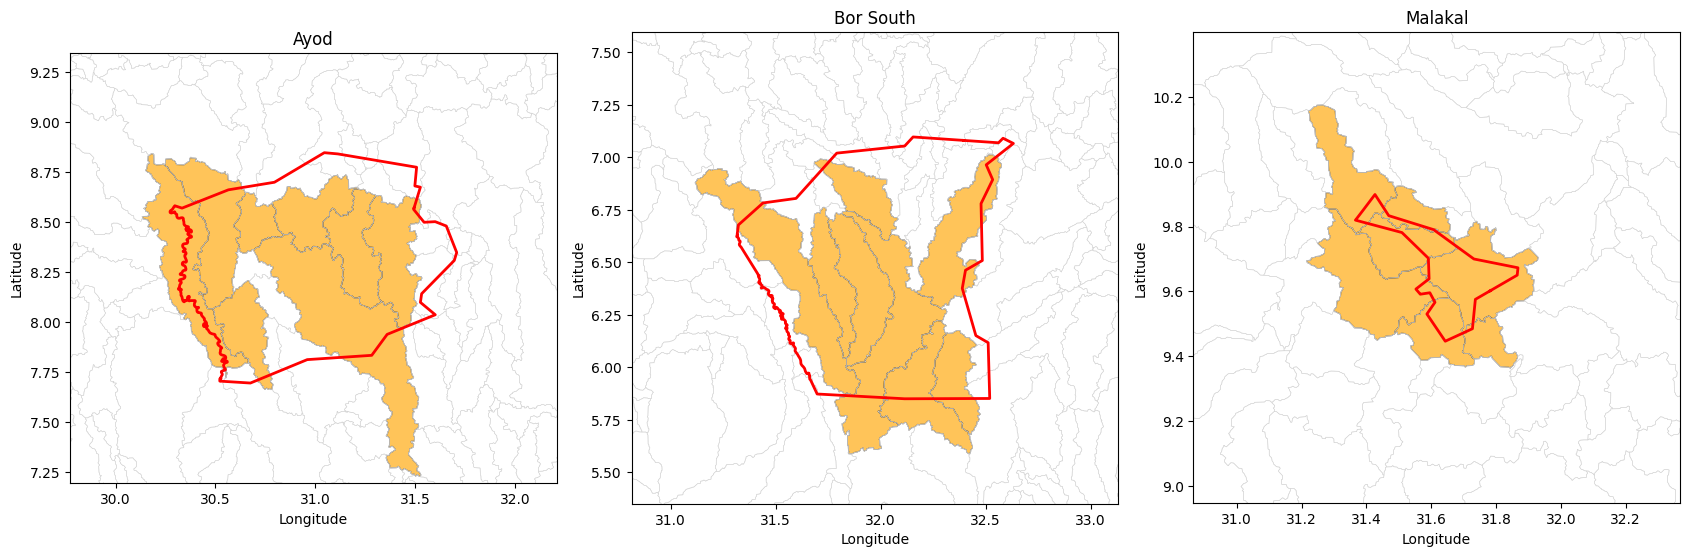

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(17, 7))

for ax, region_name in zip(axes, STUDY_AREAS):
    area_geom = study_areas.loc[
        study_areas["adm2_name"].eq(region_name), "geometry"
    ].iloc[0]

    # Zoom around this administrative area
    minx, miny, maxx, maxy = area_geom.bounds
    x_margin = 0.5
    y_margin = 0.5

    # Nearby level-8 basins
    nearby = basins_l8.cx[
        minx - x_margin:maxx + x_margin,
        miny - y_margin:maxy + y_margin
    ]

    nearby.boundary.plot(
        ax=ax, color="lightgrey", linewidth=0.35
    )

    # Candidate basins
    region_candidates = candidate_geoms.loc[
        candidate_geoms["area"].eq(region_name)
    ]

    for _, candidate in region_candidates.iterrows():
        geom = candidate.geometry
        polygons = (
            list(geom.geoms)
            if geom.geom_type == "MultiPolygon"
            else [geom]
        )

        for polygon in polygons:
            x, y = polygon.exterior.xy
            ax.fill(x, y, color="orange", alpha=0.65,
                    edgecolor="black", linewidth=0.6)

    # Administrative boundary
    x, y = area_geom.exterior.xy
    ax.plot(x, y, color="red", linewidth=2)

    ax.set_xlim(minx - x_margin, maxx + x_margin)
    ax.set_ylim(miny - y_margin, maxy + y_margin)
    ax.set_title(region_name)
    ax.set_aspect("equal")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [54]:
connectivity_check = candidate_geoms[
    ["area", "HYBAS_ID", "admin_overlap_fraction"]
].copy()

connectivity_check["NEXT_DOWN"] = (
    connectivity_check["HYBAS_ID"].map(downstream_lookup)
)

connectivity_check["SUB_AREA_km2"] = (
    connectivity_check["HYBAS_ID"]
    .map(basin_lookup_l8["SUB_AREA"])
)

connectivity_check["UP_AREA_km2"] = (
    connectivity_check["HYBAS_ID"]
    .map(basin_lookup_l8["UP_AREA"])
)

connectivity_check = connectivity_check.sort_values(
    ["area", "admin_overlap_fraction"],
    ascending=[True, False]
)

display(connectivity_check.round(3))

,area,HYBAS_ID,admin_overlap_fraction,NEXT_DOWN,SUB_AREA_km2,UP_AREA_km2
11,Ayod,1080886390,0.196,1080876750,3956.6,12150.6
7,Ayod,1080874940,0.103,1080869140,1413.6,1413.8
8,Ayod,1080874930,0.088,1080869140,1185.2,1185.5
12,Ayod,1080868170,0.087,1080852020,1703.7,1704.2
10,Ayod,1080876640,0.078,1080841720,1054.1,1054.1
14,Ayod,1080892610,0.070,1080886380,988.9,988.9
13,Ayod,1080868370,0.062,1080852020,2214.6,546857.8
9,Ayod,1080876750,0.039,1080841720,527.9,18659.0
20,Bor South,1080947990,0.135,1080943000,2372.9,2373.5
17,Bor South,1080951620,0.127,1080950610,2403.2,2403.4


In [55]:
# Trace downstream from each candidate for up to 12 basin links
chain_rows = []

for _, row in connectivity_check.iterrows():
    basin_id = int(row["HYBAS_ID"])
    current_id = basin_id

    for step in range(13):
        chain_rows.append({
            "area": row["area"],
            "candidate_id": basin_id,
            "step_downstream": step,
            "basin_id": current_id,
            "next_down": downstream_lookup.get(current_id, 0)
        })

        next_id = downstream_lookup.get(current_id, 0)
        if next_id == 0 or next_id == current_id:
            break

        current_id = int(next_id)

downstream_chains = pd.DataFrame(chain_rows)

display(
    downstream_chains.loc[downstream_chains["step_downstream"].le(5)]
    .sort_values(["area", "candidate_id", "step_downstream"])
)

,area,candidate_id,step_downstream,basin_id,next_down
39,Ayod,1080868170,0,1080868170,1080852020
40,Ayod,1080868170,1,1080852020,1080845440
41,Ayod,1080868170,2,1080845440,1080837890
42,Ayod,1080868170,3,1080837890,1080840450
43,Ayod,1080868170,4,1080840450,1080841440
...,...,...,...,...,...
287,Malakal,1080843790,1,1080845900,1080843040
288,Malakal,1080843790,2,1080843040,1080835180
289,Malakal,1080843790,3,1080835180,1080828670
290,Malakal,1080843790,4,1080828670,1080819070


In [56]:
# Compare downstream links among candidates within each study area
candidate_chain_summary = (
    downstream_chains
    .groupby(["area", "candidate_id"])
    .agg(
        links_traced=("step_downstream", "max"),
        downstream_basins=("basin_id", "nunique"),
        terminal_basin=("basin_id", "last")
    )
    .reset_index()
)

# Find downstream basins reached by multiple candidates
basin_convergence = (
    downstream_chains
    .groupby(["area", "basin_id"])
    .agg(
        n_candidate_chains=("candidate_id", "nunique"),
        candidate_ids=("candidate_id", lambda x: sorted(set(x)))
    )
    .reset_index()
    .query("n_candidate_chains > 1")
    .sort_values(["area", "n_candidate_chains"], ascending=[True, False])
)

display(candidate_chain_summary)
display(basin_convergence.head(30))

,area,candidate_id,links_traced,downstream_basins,terminal_basin
0,Ayod,1080868170,12,13,1080817590
1,Ayod,1080868370,12,13,1080817590
2,Ayod,1080874930,12,13,1080783860
3,Ayod,1080874940,12,13,1080783860
4,Ayod,1080876640,12,13,1080763740
5,Ayod,1080876750,12,13,1080763740
6,Ayod,1080886390,12,13,1080773750
7,Ayod,1080892610,12,13,1080783860
8,Bor South,1080940310,12,13,1080855690
9,Bor South,1080942100,12,13,1080817590


,area,basin_id,n_candidate_chains,candidate_ids
5,Ayod,1080817590,8,"[1080868170, 1080868370, 1080874930, 108087494..."
6,Ayod,1080819070,8,"[1080868170, 1080868370, 1080874930, 108087494..."
7,Ayod,1080828670,8,"[1080868170, 1080868370, 1080874930, 108087494..."
8,Ayod,1080835180,8,"[1080868170, 1080868370, 1080874930, 108087494..."
14,Ayod,1080843030,8,"[1080868170, 1080868370, 1080874930, 108087494..."
2,Ayod,1080783860,6,"[1080874930, 1080874940, 1080876640, 108087675..."
3,Ayod,1080798250,6,"[1080874930, 1080874940, 1080876640, 108087675..."
4,Ayod,1080800150,6,"[1080874930, 1080874940, 1080876640, 108087675..."
15,Ayod,1080844660,6,"[1080868170, 1080868370, 1080876640, 108087675..."
13,Ayod,1080841720,4,"[1080876640, 1080876750, 1080886390, 1080892610]"


In [57]:
candidate_networks = []

for _, row in connectivity_check.iterrows():
    candidate_id = int(row["HYBAS_ID"])
    upstream_ids = trace_upstream(candidate_id, upstream_lookup)

    network = basins_l8.loc[
        basins_l8["HYBAS_ID"].isin(upstream_ids)
    ]

    candidate_networks.append({
        "area": row["area"],
        "candidate_id": candidate_id,
        "candidate_sub_area_km2": row["SUB_AREA_km2"],
        "candidate_up_area_km2": row["UP_AREA_km2"],
        "n_upstream_basins": len(network),
        "sum_sub_area_km2": network["SUB_AREA"].sum(),
        "max_up_area_km2": network["UP_AREA"].max()
    })

candidate_network_summary = pd.DataFrame(candidate_networks)

display(
    candidate_network_summary.sort_values(
        ["area", "candidate_up_area_km2"],
        ascending=[True, True]
    ).round(1)
)

,area,candidate_id,candidate_sub_area_km2,candidate_up_area_km2,n_upstream_basins,sum_sub_area_km2,max_up_area_km2
5,Ayod,1080892610,988.9,988.9,1,988.9,988.9
4,Ayod,1080876640,1054.1,1054.1,1,1054.1,1054.1
2,Ayod,1080874930,1185.2,1185.5,1,1185.2,1185.5
1,Ayod,1080874940,1413.6,1413.8,1,1413.6,1413.8
3,Ayod,1080868170,1703.7,1704.2,1,1703.7,1704.2
0,Ayod,1080886390,3956.6,12150.6,13,12152.1,12150.6
7,Ayod,1080876750,527.9,18659.0,23,18660.2,18659.0
6,Ayod,1080868370,2214.6,546857.8,862,546844.2,546857.8
13,Bor South,1080942100,781.0,781.0,1,781.0,781.0
15,Bor South,1080974660,819.5,819.6,1,819.5,819.6


In [58]:
# Use the existing HydroRIVERS layer and candidate basin polygons
rivers_l8_crs = rivers.to_crs(basins_l8.crs)

river_rows = []

for _, candidate in candidate_geoms.iterrows():
    basin_id = int(candidate["HYBAS_ID"])
    basin_geom = candidate.geometry

    # River segments intersecting the candidate basin
    intersecting = rivers_l8_crs.loc[
        rivers_l8_crs.intersects(basin_geom)
    ]

    river_rows.append({
        "area": candidate["area"],
        "HYBAS_ID": basin_id,
        "admin_overlap_fraction": candidate["admin_overlap_fraction"],
        "n_river_segments": len(intersecting),
        "largest_river_id": (
            int(intersecting.loc[
                intersecting["LENGTH_KM"].idxmax(), "HYRIV_ID"
            ])
            if not intersecting.empty else None
        ),
        "largest_river_length_km": (
            intersecting["LENGTH_KM"].max()
            if not intersecting.empty else np.nan
        ),
        "largest_river_catchment_km2": (
            intersecting["CATCH_SKM"].max()
            if not intersecting.empty else np.nan
        )
    })

candidate_river_check = pd.DataFrame(river_rows)

display(
    candidate_river_check.sort_values(
        ["area", "admin_overlap_fraction"],
        ascending=[True, False]
    ).round(2)
)

,area,HYBAS_ID,admin_overlap_fraction,n_river_segments,largest_river_id,largest_river_length_km,largest_river_catchment_km2
11,Ayod,1080886390,0.20,190,10702357,20.80,97.94
7,Ayod,1080874940,0.10,61,10711952,19.55,111.12
8,Ayod,1080874930,0.09,43,10706519,15.48,67.55
12,Ayod,1080868170,0.09,68,10694936,31.09,159.63
10,Ayod,1080876640,0.08,53,10697381,11.02,69.85
14,Ayod,1080892610,0.07,50,10732546,16.77,112.09
13,Ayod,1080868370,0.06,110,10726852,17.76,106.16
9,Ayod,1080876750,0.04,24,10698150,14.53,56.05
20,Bor South,1080947990,0.13,109,10772253,21.61,107.29
17,Bor South,1080951620,0.13,107,10821878,17.53,79.25


In [59]:
# River segments intersecting each study-area boundary
admin_river_rows = []

rivers_wgs84 = rivers.to_crs(study_areas.crs)

for _, area_row in study_areas.iterrows():
    region_name = area_row["adm2_name"]
    area_geom = area_row.geometry

    local_rivers = rivers_wgs84.loc[
        rivers_wgs84.intersects(area_geom)
    ].copy()

    if local_rivers.empty:
        admin_river_rows.append({
            "area": region_name,
            "n_river_segments": 0,
            "river_ids": [],
            "main_river_ids": [],
            "basin_l12_ids": []
        })
        continue

    admin_river_rows.append({
        "area": region_name,
        "n_river_segments": len(local_rivers),
        "river_ids": local_rivers["HYRIV_ID"].astype(int).tolist()[:20],
        "main_river_ids": local_rivers["MAIN_RIV"].dropna().astype(int).unique().tolist()[:20],
        "basin_l12_ids": local_rivers["HYBAS_L12"].dropna().astype(int).unique().tolist()[:20]
    })

admin_river_summary = pd.DataFrame(admin_river_rows)
display(admin_river_summary)

,area,n_river_segments,river_ids,main_river_ids,basin_l12_ids
0,Ayod,662,"[10680339, 10680340, 10681067, 10681068, 10681...",[10047863],"[1121978640, 1121977270, 1120868940, 112086648..."
1,Bor South,626,"[10760878, 10761098, 10761665, 10761666, 10762...",[10047863],"[1122006050, 1120933530, 1120934990, 112093521..."
2,Malakal,49,"[10635762, 10636436, 10638628, 10638805, 10640...",[10047863],"[1120820600, 1120826310, 1121960440, 112082645..."


In [60]:
river_check_rows = []

for _, area_row in study_areas.iterrows():
    region_name = area_row["adm2_name"]
    area_geom = area_row.geometry

    local_rivers = rivers_wgs84.loc[
        rivers_wgs84.intersects(area_geom)
    ].copy()

    local_rivers = local_rivers.sort_values(
        "LENGTH_KM", ascending=False
    ).head(10)

    for _, river in local_rivers.iterrows():
        river_check_rows.append({
            "area": region_name,
            "HYRIV_ID": int(river["HYRIV_ID"]),
            "MAIN_RIV": int(river["MAIN_RIV"]),
            "LENGTH_KM": river["LENGTH_KM"],
            "CATCH_SKM": river["CATCH_SKM"],
            "UPLAND_SKM": river["UPLAND_SKM"],
            "HYBAS_L12": int(river["HYBAS_L12"]),
            "NEXT_DOWN": int(river["NEXT_DOWN"])
        })

admin_river_detail = pd.DataFrame(river_check_rows)

display(
    admin_river_detail.sort_values(
        ["area", "LENGTH_KM"],
        ascending=[True, False]
    ).round(1)
)

,area,HYRIV_ID,MAIN_RIV,LENGTH_KM,CATCH_SKM,UPLAND_SKM,HYBAS_L12,NEXT_DOWN
0,Ayod,10694936,10047863,31.1,159.6,275.9,1120879150,10694586
1,Ayod,10702357,10047863,20.8,94.7,94.7,1120886390,10702356
2,Ayod,10683444,10047863,19.6,90.8,3256.8,1120863540,10677812
3,Ayod,10711952,10047863,19.6,111.1,111.1,1120889340,10705920
4,Ayod,10693989,10047863,18.3,86.2,1285.1,1120873900,10688643
5,Ayod,10726852,10047863,17.8,64.0,544834.8,1121993850,10721061
6,Ayod,10718114,10047863,17.6,71.2,232.1,1120900360,10718113
7,Ayod,10729128,10047863,17.6,71.0,71.0,1121995420,10724963
8,Ayod,10701611,10047863,16.9,53.7,53.7,1120879770,10696263
9,Ayod,10732546,10047863,16.8,112.1,112.1,1121994930,10726666


In [61]:
# Trace downstream river IDs from the largest intersecting segments
river_chain_rows = []

for _, row in admin_river_detail.iterrows():
    current_id = int(row["HYRIV_ID"])

    for step in range(21):
        river_chain_rows.append({
            "area": row["area"],
            "start_river_id": int(row["HYRIV_ID"]),
            "step_downstream": step,
            "river_id": current_id
        })

        matches = rivers.loc[rivers["HYRIV_ID"].eq(current_id), "NEXT_DOWN"]
        if matches.empty:
            break

        next_id = int(matches.iloc[0])
        if next_id == 0 or next_id == current_id:
            break

        current_id = next_id

river_chains = pd.DataFrame(river_chain_rows)

display(
    river_chains.groupby(["area", "start_river_id"])
    .agg(
        links_traced=("step_downstream", "max"),
        last_river_id=("river_id", "last")
    )
    .reset_index()
)

,area,start_river_id,links_traced,last_river_id
0,Ayod,10683444,20,10658284
1,Ayod,10693989,20,10664102
2,Ayod,10694936,20,10665402
3,Ayod,10701611,20,10667805
4,Ayod,10702357,20,10681438
5,Ayod,10711952,20,10677812
6,Ayod,10718114,20,10704475
7,Ayod,10726852,20,10704062
8,Ayod,10729128,20,10709467
9,Ayod,10732546,20,10700600


In [62]:
# Load level-12 basins already referenced in the notebook
basins_l12 = gpd.read_file(
    HYDROBASINS_DIR / "hybas_af_lev12_v1c.shp"
)

area_l12_rows = []

for _, area_row in study_areas.iterrows():
    region_name = area_row["adm2_name"]
    area_geom = area_row.geometry

    local_rivers = rivers_wgs84.loc[
        rivers_wgs84.intersects(area_geom)
    ]

    l12_ids = local_rivers["HYBAS_L12"].dropna().astype("int64").unique()

    local_l12 = basins_l12.loc[
        basins_l12["HYBAS_ID"].isin(l12_ids)
    ].copy()

    if not local_l12.empty:
        local_l12 = local_l12.to_crs(study_areas.crs)
        local_l12["area_overlap"] = local_l12.geometry.intersection(
            area_geom
        ).area / local_l12.geometry.area

        for _, basin in local_l12.iterrows():
            area_l12_rows.append({
                "area": region_name,
                "HYBAS_ID_L12": int(basin["HYBAS_ID"]),
                "NEXT_DOWN": int(basin["NEXT_DOWN"]),
                "SUB_AREA_km2": basin["SUB_AREA"],
                "UP_AREA_km2": basin["UP_AREA"],
                "admin_overlap_fraction": basin["area_overlap"]
            })

area_l12_summary = pd.DataFrame(area_l12_rows)

display(
    area_l12_summary.sort_values(
        ["area", "admin_overlap_fraction"],
        ascending=[True, False]
    ).groupby("area").head(10).round(4)
)

C:\Users\20242408\AppData\Local\Temp\ipykernel_26692\1704708973.py:26: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  ).area / local_l12.geometry.area
C:\Users\20242408\AppData\Local\Temp\ipykernel_26692\1704708973.py:26: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  ).area / local_l12.geometry.area
C:\Users\20242408\AppData\Local\Temp\ipykernel_26692\1704708973.py:26: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  ).area / local_l12.geometry.area


,area,HYBAS_ID_L12,NEXT_DOWN,SUB_AREA_km2,UP_AREA_km2,admin_overlap_fraction
3,Ayod,1121979270,1121978640,134.3,134.3,1.0000
37,Ayod,1120886640,1120882130,111.2,374.8,1.0000
62,Ayod,1120892610,1121987870,76.3,988.5,1.0000
108,Ayod,1121988240,1121987610,136.9,310.8,1.0000
20,Ayod,1120874530,1120869860,30.9,19744.2,1.0000
30,Ayod,1121985450,1120885990,179.3,179.4,1.0000
64,Ayod,1120892800,1120888990,186.7,186.7,1.0000
94,Ayod,1120882740,1120879470,135.7,614.1,1.0000
17,Ayod,1120879770,1120874940,142.4,142.5,1.0000
19,Ayod,1120879990,1120879780,151.2,968.5,1.0000


In [63]:
# Recalculate level-12 basin overlap in a projected CRS
AREA_CRS = "EPSG:32636"

study_areas_projected = study_areas.to_crs(AREA_CRS)
basins_l12_projected = basins_l12.to_crs(AREA_CRS)

area_l12_rows = []

for _, area_row in study_areas_projected.iterrows():
    region_name = area_row["adm2_name"]
    area_geom = area_row.geometry

    local_rivers = rivers_wgs84.loc[
        rivers_wgs84.intersects(
            study_areas.loc[
                study_areas["adm2_name"].eq(region_name), "geometry"
            ].iloc[0]
        )
    ]

    l12_ids = (
        local_rivers["HYBAS_L12"]
        .dropna()
        .astype("int64")
        .unique()
    )

    local_l12 = basins_l12_projected.loc[
        basins_l12_projected["HYBAS_ID"].isin(l12_ids)
    ].copy()

    for _, basin in local_l12.iterrows():
        basin_area = basin.geometry.area

        area_l12_rows.append({
            "area": region_name,
            "HYBAS_ID_L12": int(basin["HYBAS_ID"]),
            "NEXT_DOWN": int(basin["NEXT_DOWN"]),
            "SUB_AREA_km2": basin["SUB_AREA"],
            "UP_AREA_km2": basin["UP_AREA"],
            "admin_overlap_fraction": (
                basin.geometry.intersection(area_geom).area / basin_area
                if basin_area > 0 else np.nan
            )
        })

area_l12_summary = pd.DataFrame(area_l12_rows)

display(
    area_l12_summary.sort_values(
        ["area", "admin_overlap_fraction"],
        ascending=[True, False]
    ).groupby("area").head(10).round(3)
)

,area,HYBAS_ID_L12,NEXT_DOWN,SUB_AREA_km2,UP_AREA_km2,admin_overlap_fraction
35,Ayod,1121982590,1120876640,161.8,931.7,1.000
88,Ayod,1120879150,1120878900,136.4,275.9,1.000
89,Ayod,1121990700,1120895160,191.8,191.8,1.000
33,Ayod,1120883490,1120882120,162.3,162.3,1.000
95,Ayod,1120882750,1120879470,131.1,131.2,1.000
20,Ayod,1120874530,1120869860,30.9,19744.2,1.000
39,Ayod,1121983600,1121983160,132.8,18403.0,1.000
55,Ayod,1121985390,1121984630,134.7,134.8,1.000
56,Ayod,1121981580,1121981970,165.9,165.9,1.000
71,Ayod,1121987620,1121987320,183.6,183.6,1.000


In [68]:
# Compare level-12 polygons spatially with the level-8 candidate polygons
l12_projected = basins_l12.to_crs("EPSG:32636")
candidates_projected = candidate_geoms.to_crs("EPSG:32636")

spatial_link_rows = []

for _, candidate in candidates_projected.iterrows():
    candidate_geom = candidate.geometry
    candidate_area = candidate_geom.area

    nearby_l12 = l12_projected.loc[
        l12_projected.intersects(candidate_geom)
    ]

    for _, basin in nearby_l12.iterrows():
        intersection_area = basin.geometry.intersection(candidate_geom).area

        if intersection_area > 0:
            spatial_link_rows.append({
                "area": candidate["area"],
                "candidate_HYBAS_ID_L8": int(candidate["HYBAS_ID"]),
                "HYBAS_ID_L12": int(basin["HYBAS_ID"]),
                "candidate_area_km2": candidate_area / 1e6,
                "intersection_km2": intersection_area / 1e6,
                "candidate_coverage_fraction": intersection_area / candidate_area
            })

l12_spatial_links = pd.DataFrame(spatial_link_rows)

display(
    l12_spatial_links.sort_values(
        ["area", "candidate_HYBAS_ID_L8", "intersection_km2"],
        ascending=[True, True, False]
    ).groupby(["area", "candidate_HYBAS_ID_L8"]).head(3).round(3)
)

,area,candidate_HYBAS_ID_L8,HYBAS_ID_L12,candidate_area_km2,intersection_km2,candidate_coverage_fraction
93,Ayod,1080868170,1121988850,1698.453,173.080,0.102
91,Ayod,1080868170,1121987610,1698.453,167.212,0.098
81,Ayod,1080868170,1121980510,1698.453,161.605,0.095
104,Ayod,1080868370,1121988960,2208.236,215.808,0.098
94,Ayod,1080868370,1120868370,2208.236,207.797,0.094
...,...,...,...,...,...,...
9,Malakal,1080834950,1120834320,842.257,186.156,0.221
8,Malakal,1080834950,1120834150,842.257,169.508,0.201
12,Malakal,1080835180,1121967960,358.610,190.377,0.531
11,Malakal,1080835180,1120835180,358.610,168.233,0.469


In [69]:
l12_coverage_summary = (
    l12_spatial_links
    .groupby(["area", "candidate_HYBAS_ID_L8"])
    .agg(
        n_l12_intersections=("HYBAS_ID_L12", "nunique"),
        summed_intersection_km2=("intersection_km2", "sum"),
        candidate_area_km2=("candidate_area_km2", "first"),
        summed_coverage_fraction=("candidate_coverage_fraction", "sum")
    )
    .reset_index()
)

l12_coverage_summary["coverage_pct"] = (
    l12_coverage_summary["summed_coverage_fraction"] * 100
)

display(
    l12_coverage_summary.sort_values(
        ["area", "coverage_pct"],
        ascending=[True, False]
    ).round(1)
)

,area,candidate_HYBAS_ID_L8,n_l12_intersections,summed_intersection_km2,candidate_area_km2,summed_coverage_fraction,coverage_pct
3,Ayod,1080874940,11,1407.6,1407.6,1.0,100.0
2,Ayod,1080874930,9,1180.4,1180.4,1.0,100.0
5,Ayod,1080876750,4,526.1,526.1,1.0,100.0
6,Ayod,1080886390,26,3940.8,3940.8,1.0,100.0
4,Ayod,1080876640,8,1050.1,1050.1,1.0,100.0
7,Ayod,1080892610,8,985.6,985.6,1.0,100.0
1,Ayod,1080868370,16,2208.2,2208.2,1.0,100.0
0,Ayod,1080868170,14,1698.5,1698.5,1.0,100.0
14,Bor South,1080974660,6,815.4,815.4,1.0,100.0
12,Bor South,1080951620,17,2391.6,2391.6,1.0,100.0


In [70]:
# Identify whether shortlisted level-8 candidates are downstream
# of other shortlisted candidates
candidate_nesting_rows = []

for area in STUDY_AREAS:
    area_candidates = candidate_geoms.loc[
        candidate_geoms["area"].eq(area), "HYBAS_ID"
    ].astype("int64").tolist()

    for candidate_id in area_candidates:
        current_id = int(candidate_id)
        seen = set()
        downstream_candidates = []

        # Follow downstream links, stopping when the chain repeats,
        # reaches a terminal basin, or exceeds 100 links.
        for step in range(100):
            next_id = int(downstream_lookup.get(current_id, 0))

            if next_id == 0 or next_id == current_id or next_id in seen:
                break

            seen.add(next_id)

            if next_id in area_candidates:
                downstream_candidates.append(next_id)

            current_id = next_id

        candidate_nesting_rows.append({
            "area": area,
            "candidate_id": int(candidate_id),
            "downstream_candidate_ids": downstream_candidates,
            "n_downstream_candidates": len(downstream_candidates)
        })

candidate_nesting = pd.DataFrame(candidate_nesting_rows)

display(
    candidate_nesting.sort_values(
        ["area", "n_downstream_candidates"],
        ascending=[True, False]
    )
)

,area,candidate_id,downstream_candidate_ids,n_downstream_candidates
4,Ayod,1080886390,[1080876750],1
7,Ayod,1080892610,[1080876750],1
0,Ayod,1080874940,[],0
1,Ayod,1080874930,[],0
2,Ayod,1080876750,[],0
3,Ayod,1080876640,[],0
5,Ayod,1080868170,[],0
6,Ayod,1080868370,[],0
8,Bor South,1080942100,[],0
9,Bor South,1080950600,[],0


In [71]:
final_candidate_review = (
    connectivity_check[
        ["area", "HYBAS_ID", "admin_overlap_fraction",
         "SUB_AREA_km2", "UP_AREA_km2"]
    ]
    .merge(
        candidate_nesting[
            ["area", "candidate_id", "n_downstream_candidates",
             "downstream_candidate_ids"]
        ],
        left_on=["area", "HYBAS_ID"],
        right_on=["area", "candidate_id"],
        how="left"
    )
    .drop(columns="candidate_id")
    .sort_values(
        ["area", "admin_overlap_fraction"],
        ascending=[True, False]
    )
)

display(final_candidate_review.round(2))

,area,HYBAS_ID,admin_overlap_fraction,SUB_AREA_km2,UP_AREA_km2,n_downstream_candidates,downstream_candidate_ids
0,Ayod,1080886390,0.20,3956.6,12150.6,1,[1080876750]
1,Ayod,1080874940,0.10,1413.6,1413.8,0,[]
2,Ayod,1080874930,0.09,1185.2,1185.5,0,[]
3,Ayod,1080868170,0.09,1703.7,1704.2,0,[]
4,Ayod,1080876640,0.08,1054.1,1054.1,0,[]
5,Ayod,1080892610,0.07,988.9,988.9,1,[1080876750]
6,Ayod,1080868370,0.06,2214.6,546857.8,0,[]
7,Ayod,1080876750,0.04,527.9,18659.0,0,[]
8,Bor South,1080947990,0.13,2372.9,2373.5,0,[]
9,Bor South,1080951620,0.13,2403.2,2403.4,0,[]


In [72]:
final_candidate_review = (
    connectivity_check[
        ["area", "HYBAS_ID", "admin_overlap_fraction",
         "SUB_AREA_km2", "UP_AREA_km2"]
    ]
    .merge(
        candidate_nesting[
            ["area", "candidate_id", "n_downstream_candidates",
             "downstream_candidate_ids"]
        ],
        left_on=["area", "HYBAS_ID"],
        right_on=["area", "candidate_id"],
        how="left"
    )
    .drop(columns="candidate_id")
    .sort_values(
        ["area", "admin_overlap_fraction"],
        ascending=[True, False]
    )
)

display(final_candidate_review.round(2))

,area,HYBAS_ID,admin_overlap_fraction,SUB_AREA_km2,UP_AREA_km2,n_downstream_candidates,downstream_candidate_ids
0,Ayod,1080886390,0.20,3956.6,12150.6,1,[1080876750]
1,Ayod,1080874940,0.10,1413.6,1413.8,0,[]
2,Ayod,1080874930,0.09,1185.2,1185.5,0,[]
3,Ayod,1080868170,0.09,1703.7,1704.2,0,[]
4,Ayod,1080876640,0.08,1054.1,1054.1,0,[]
5,Ayod,1080892610,0.07,988.9,988.9,1,[1080876750]
6,Ayod,1080868370,0.06,2214.6,546857.8,0,[]
7,Ayod,1080876750,0.04,527.9,18659.0,0,[]
8,Bor South,1080947990,0.13,2372.9,2373.5,0,[]
9,Bor South,1080951620,0.13,2403.2,2403.4,0,[]


In [73]:
# Provisional candidates for targeted river-connection inspection
priority_ids = {
    "Ayod": [1080886390, 1080874940, 1080874930],
    "Bor South": [1080947990, 1080951620],
    "Malakal": [1080826450, 1080826310, 1080820600],
}

priority_rows = []

rivers_wgs84 = rivers.to_crs("EPSG:4326")

for region_name, basin_ids in priority_ids.items():
    area_geom = study_areas.loc[
        study_areas["adm2_name"].eq(region_name), "geometry"
    ].iloc[0]

    local_rivers = rivers_wgs84.loc[
        rivers_wgs84.intersects(area_geom)
    ]

    for basin_id in basin_ids:
        basin_geom = basins_l8.loc[
            basins_l8["HYBAS_ID"].eq(basin_id), "geometry"
        ].iloc[0]

        river_segments = local_rivers.loc[
            local_rivers.intersects(basin_geom)
        ]

        priority_rows.append({
            "area": region_name,
            "candidate_HYBAS_ID": basin_id,
            "local_river_segments_in_candidate": len(river_segments),
            "local_river_ids": river_segments["HYRIV_ID"].astype(int).tolist()[:10],
            "local_river_HYBAS_L12": (
                river_segments["HYBAS_L12"].dropna().astype(int).unique().tolist()[:10]
            )
        })

priority_river_check = pd.DataFrame(priority_rows)
display(priority_river_check)

,area,candidate_HYBAS_ID,local_river_segments_in_candidate,local_river_ids,local_river_HYBAS_L12
0,Ayod,1080886390,130,"[10702356, 10702357, 10702735, 10702736, 10703...","[1120886390, 1121987320, 1120888750, 112198762..."
1,Ayod,1080874940,61,"[10692572, 10692573, 10692747, 10692748, 10692...","[1120879790, 1120874940, 1120879780, 112087977..."
2,Ayod,1080874930,43,"[10691527, 10691528, 10693659, 10695693, 10697...","[1120874930, 1120882910, 1120882120, 112088349..."
3,Bor South,1080947990,93,"[10777695, 10778667, 10779256, 10779903, 10779...","[1120951480, 1120953690, 1120951610, 112094906..."
4,Bor South,1080951620,83,"[10780112, 10780913, 10782706, 10783475, 10784...","[1120951620, 1122012660, 1120956250, 112095649..."
5,Malakal,1080826450,7,"[10640503, 10641205, 10641533, 10641534, 10641...","[1120826450, 1121963670, 1121963570]"
6,Malakal,1080826310,1,[10638628],[1120826310]
7,Malakal,1080820600,3,"[10635762, 10636436, 10638805]","[1120820600, 1121960440]"


In [76]:
# Step 1: Review the provisional catchment shortlist

shortlist_review = (
    candidate_network_summary
    .merge(
        candidate_shortlist[
            ["area", "HYBAS_ID", "admin_overlap_fraction"]
        ].rename(columns={"HYBAS_ID": "candidate_id"}),
        on=["area", "candidate_id"],
        how="left"
    )
)

priority_ids = {
    "Ayod": [1080886390, 1080874940, 1080874930],
    "Bor South": [1080947990, 1080951620],
    "Malakal": [1080826450, 1080826310, 1080820600],
}

shortlist_review = shortlist_review[
    shortlist_review.apply(
        lambda row: int(row["candidate_id"]) in priority_ids.get(row["area"], []),
        axis=1
    )
].copy()

display(
    shortlist_review[
        [
            "area",
            "candidate_id",
            "admin_overlap_fraction",
            "candidate_sub_area_km2",
            "candidate_up_area_km2",
            "n_upstream_basins",
            "sum_sub_area_km2",
            "max_up_area_km2",
        ]
    ].sort_values(
        ["area", "admin_overlap_fraction"],
        ascending=[True, False]
    )
)

,area,candidate_id,admin_overlap_fraction,candidate_sub_area_km2,candidate_up_area_km2,n_upstream_basins,sum_sub_area_km2,max_up_area_km2
0,Ayod,1080886390,0.195882,3956.6,12150.6,13,12152.1,12150.6
1,Ayod,1080874940,0.102930,1413.6,1413.8,1,1413.6,1413.8
2,Ayod,1080874930,0.087756,1185.2,1185.5,1,1185.2,1185.5
8,Bor South,1080947990,0.134970,2372.9,2373.5,1,2372.9,2373.5
9,Bor South,1080951620,0.126873,2403.2,2403.4,1,2403.2,2403.4
17,Malakal,1080826450,0.188068,399.7,399.7,1,399.7,399.7
19,Malakal,1080820600,0.055998,532.6,1177.1,3,1177.3,1177.1
21,Malakal,1080826310,0.040511,208.8,1777.7,5,1777.1,1777.7


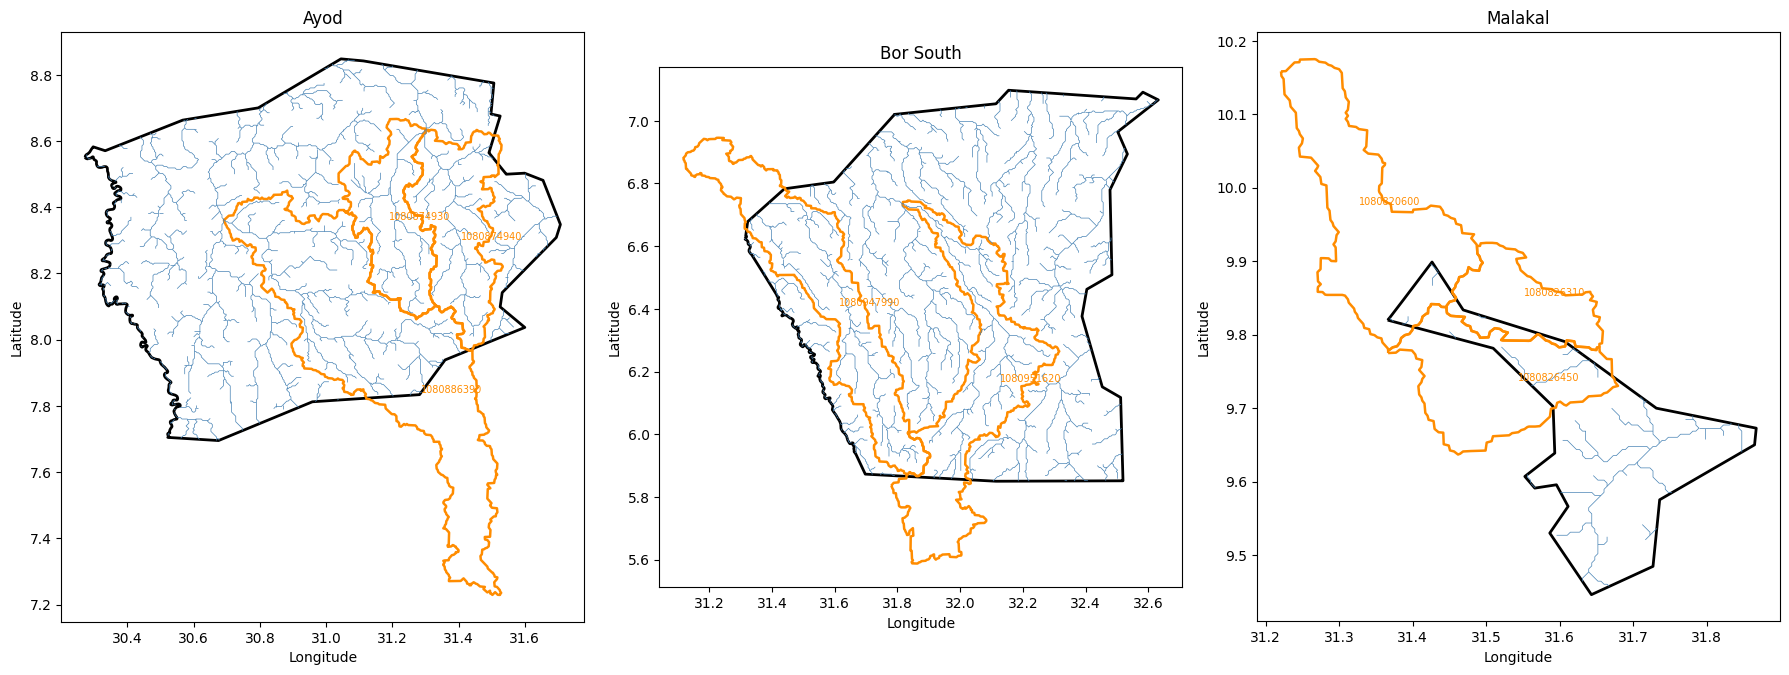

In [77]:
# Step 1b: Map shortlisted catchments and river network

import matplotlib.pyplot as plt

priority_ids = {
    "Ayod": [1080886390, 1080874940, 1080874930],
    "Bor South": [1080947990, 1080951620],
    "Malakal": [1080826450, 1080826310, 1080820600],
}

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, area in zip(axes, STUDY_AREAS):
    area_geom = study_areas.loc[
        study_areas["adm2_name"] == area
    ]

    area_candidates = candidate_geoms.loc[
        (candidate_geoms["area"] == area)
        & (candidate_geoms["HYBAS_ID"].isin(priority_ids[area]))
    ]

    # Show the local administrative boundary
    area_geom.boundary.plot(ax=ax, color="black", linewidth=2)

    # Show candidate catchment boundaries
    area_candidates.boundary.plot(
        ax=ax, color="darkorange", linewidth=1.8
    )

    # Show rivers in the local study area
    local_rivers = gpd.clip(
        rivers_wgs84,
        area_geom.to_crs(rivers_wgs84.crs)
    )
    local_rivers.plot(ax=ax, color="steelblue", linewidth=0.5)

    # Label each candidate at its centroid
    for _, row in area_candidates.iterrows():
        point = row.geometry.representative_point()
        ax.annotate(
            str(int(row["HYBAS_ID"])),
            (point.x, point.y),
            fontsize=7,
            color="darkorange"
        )

    ax.set_title(area)
    ax.set_aspect("equal")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [78]:
# Step 2: Inspect downstream links between shortlisted candidates

priority_ids = {
    "Ayod": [1080886390, 1080874940, 1080874930],
    "Bor South": [1080947990, 1080951620],
    "Malakal": [1080826450, 1080826310, 1080820600],
}

candidate_ids = [
    basin_id
    for ids in priority_ids.values()
    for basin_id in ids
]

downstream_check = basin_connectivity.loc[
    basin_connectivity["HYBAS_ID"].isin(candidate_ids),
    ["HYBAS_ID", "NEXT_DOWN", "SUB_AREA", "UP_AREA"]
].copy()

downstream_check["area"] = downstream_check["HYBAS_ID"].map(
    {
        basin_id: area
        for area, ids in priority_ids.items()
        for basin_id in ids
    }
)

downstream_check["NEXT_DOWN_is_shortlisted"] = (
    downstream_check["NEXT_DOWN"].isin(candidate_ids)
)

display(
    downstream_check[
        [
            "area",
            "HYBAS_ID",
            "NEXT_DOWN",
            "SUB_AREA",
            "UP_AREA",
            "NEXT_DOWN_is_shortlisted",
        ]
    ].sort_values(["area", "HYBAS_ID"])
)

,area,HYBAS_ID,NEXT_DOWN,SUB_AREA,UP_AREA,NEXT_DOWN_is_shortlisted
24276,Ayod,1080874930,1080869140,1185.2,1185.5,False
24275,Ayod,1080874940,1080869140,1413.6,1413.8,False
24343,Ayod,1080886390,1080876750,3956.6,12150.6,False
24719,Bor South,1080947990,1080943000,2372.9,2373.5,False
24654,Bor South,1080951620,1080950610,2403.2,2403.4,False
24159,Malakal,1080820600,1080826310,532.6,1177.1,True
24130,Malakal,1080826310,1080823890,208.8,1777.7,False
24129,Malakal,1080826450,1080823890,399.7,399.7,False


In [79]:
# Step 2b: Trace downstream paths for shortlisted catchments

def trace_downstream(start_basin_id, downstream_lookup, max_steps=15):
    path = []
    current = int(start_basin_id)
    visited = set()

    for step in range(max_steps):
        if current == 0 or current in visited:
            break

        visited.add(current)
        path.append({
            "step": step,
            "HYBAS_ID": current
        })

        current = int(downstream_lookup.get(current, 0))

    return path


downstream_paths = []

for area, ids in priority_ids.items():
    for basin_id in ids:
        for item in trace_downstream(
            basin_id,
            downstream_lookup,
            max_steps=15
        ):
            downstream_paths.append({
                "area": area,
                "start_candidate": basin_id,
                **item
            })

downstream_paths = pd.DataFrame(downstream_paths)

display(
    downstream_paths.sort_values(
        ["area", "start_candidate", "step"]
    )
)

,area,start_candidate,step,HYBAS_ID
30,Ayod,1080874930,0,1080874930
31,Ayod,1080874930,1,1080869140
32,Ayod,1080874930,2,1080863540
33,Ayod,1080874930,3,1080850320
34,Ayod,1080874930,4,1080844900
...,...,...,...,...
85,Malakal,1080826450,10,1080751710
86,Malakal,1080826450,11,1080747550
87,Malakal,1080826450,12,1080743540
88,Malakal,1080826450,13,1080728710


In [80]:
# Step 2c: Identify where shortlisted downstream paths converge

path_summary = (
    downstream_paths.groupby(["area", "start_candidate"])
    .agg(
        n_steps=("HYBAS_ID", "size"),
        last_basin=("HYBAS_ID", "last"),
    )
    .reset_index()
)

# Find basins reached by more than one candidate within each study area
convergence = (
    downstream_paths.groupby(["area", "HYBAS_ID"])
    .agg(
        n_candidates=("start_candidate", "nunique"),
        candidates=("start_candidate", lambda x: sorted(set(x))),
        earliest_step=("step", "min"),
    )
    .reset_index()
)

convergence = convergence[convergence["n_candidates"] > 1]

print("Downstream path summary:")
display(path_summary)

print("\nBasins shared by multiple candidate paths:")
display(
    convergence.sort_values(
        ["area", "n_candidates"],
        ascending=[True, False]
    )
)

Downstream path summary:


,area,start_candidate,n_steps,last_basin
0,Ayod,1080874930,15,1080763740
1,Ayod,1080874940,15,1080763740
2,Ayod,1080886390,15,1080751710
3,Bor South,1080947990,15,1080843030
4,Bor South,1080951620,15,1080817590
5,Malakal,1080820600,15,1080728710
6,Malakal,1080826310,15,1080716260
7,Malakal,1080826450,15,1080716260



Basins shared by multiple candidate paths:


,area,HYBAS_ID,n_candidates,candidates,earliest_step
1,Ayod,1080763740,3,"[1080874930, 1080874940, 1080886390]",13
2,Ayod,1080773750,3,"[1080874930, 1080874940, 1080886390]",12
3,Ayod,1080783860,3,"[1080874930, 1080874940, 1080886390]",11
4,Ayod,1080798250,3,"[1080874930, 1080874940, 1080886390]",10
5,Ayod,1080800150,3,"[1080874930, 1080874940, 1080886390]",9
6,Ayod,1080817590,3,"[1080874930, 1080874940, 1080886390]",8
7,Ayod,1080819070,3,"[1080874930, 1080874940, 1080886390]",7
8,Ayod,1080828670,3,"[1080874930, 1080874940, 1080886390]",6
9,Ayod,1080835180,3,"[1080874930, 1080874940, 1080886390]",5
11,Ayod,1080843030,3,"[1080874930, 1080874940, 1080886390]",4


In [81]:
# Step 3: Compare downstream paths for Ayod candidates

ayod_paths = downstream_paths[
    (downstream_paths["area"] == "Ayod")
].copy()

display(
    ayod_paths.pivot(
        index="step",
        columns="start_candidate",
        values="HYBAS_ID"
    ).rename_axis(
        index="Downstream step",
        columns="Starting candidate"
    )
)

Starting candidate,1080874930,1080874940,1080886390
Downstream step,,,
0,1080874930,1080874940,1080886390
1,1080869140,1080869140,1080876750
2,1080863540,1080863540,1080841720
3,1080850320,1080850320,1080844660
4,1080844900,1080844900,1080843030
5,1080843030,1080843030,1080835180
6,1080835180,1080835180,1080828670
7,1080828670,1080828670,1080819070
8,1080819070,1080819070,1080817590


In [82]:
# Step 3b: Inspect river segments inside each Ayod candidate and study area

ayod_candidate_ids = [1080874930, 1080874940, 1080886390]

ayod_area = study_areas.loc[
    study_areas["adm2_name"] == "Ayod"
].to_crs(rivers.crs)

ayod_candidates = candidate_geoms.loc[
    (candidate_geoms["area"] == "Ayod")
    & (candidate_geoms["HYBAS_ID"].isin(ayod_candidate_ids))
].to_crs(rivers.crs)

river_checks = []

for _, candidate in ayod_candidates.iterrows():
    candidate_polygon = candidate.geometry
    area_polygon = ayod_area.geometry.iloc[0]

    # River segments intersecting both the candidate and Ayod
    intersects = rivers[
        rivers.geometry.intersects(candidate_polygon)
        & rivers.geometry.intersects(area_polygon)
    ].copy()

    river_checks.append({
        "candidate_id": int(candidate["HYBAS_ID"]),
        "n_river_segments": len(intersects),
        "river_segments": intersects[
            ["HYRIV_ID", "NEXT_DOWN", "MAIN_RIV",
             "LENGTH_KM", "UPLAND_SKM"]
        ].sort_values("UPLAND_SKM", ascending=False)
    })

for result in river_checks:
    print(
        f"\nCandidate {result['candidate_id']}: "
        f"{result['n_river_segments']} intersecting river segments"
    )
    display(result["river_segments"].head(10))


Candidate 1080874940: 61 intersecting river segments


,HYRIV_ID,NEXT_DOWN,MAIN_RIV,LENGTH_KM,UPLAND_SKM
693119,10693120,10689582,10047863,10.12,1413.8
693300,10693301,10693120,10047863,1.11,1344.2
694753,10694754,10693301,10047863,4.46,1313.0
694938,10694939,10694754,10047863,2.03,1150.4
696441,10696442,10694939,10047863,4.27,968.5
697197,10697198,10696442,10047863,2.42,924.5
698548,10698549,10697198,10047863,3.24,868.7
699295,10699296,10698549,10047863,2.04,826.8
700600,10700601,10699296,10047863,4.64,709.4
703129,10703130,10700601,10047863,7.34,674.4



Candidate 1080874930: 43 intersecting river segments


,HYRIV_ID,NEXT_DOWN,MAIN_RIV,LENGTH_KM,UPLAND_SKM
691527,10691528,10689582,10047863,7.89,1185.5
693658,10693659,10691528,10047863,7.07,1111.0
697383,10697384,10693659,10047863,10.21,1006.5
699660,10699661,10697384,10047863,5.94,594.0
700787,10700788,10699661,10047863,3.16,553.4
701960,10701961,10700788,10047863,2.78,510.1
704655,10704656,10701961,10047863,6.86,374.8
698732,10698733,10697384,10047863,7.93,351.6
704820,10704821,10704656,10047863,0.65,325.7
708201,10708202,10704821,10047863,10.12,313.2



Candidate 1080886390: 130 intersecting river segments


,HYRIV_ID,NEXT_DOWN,MAIN_RIV,LENGTH_KM,UPLAND_SKM
702355,10702356,10701795,10047863,3.33,12150.6
703722,10703723,10702356,10047863,7.31,12046.5
704474,10704475,10703723,10047863,6.28,11969.2
705917,10705918,10704475,10047863,4.08,11487.5
707627,10707628,10705918,10047863,7.13,11446.3
709274,10709275,10707628,10047863,4.55,11405.5
709466,10709467,10709275,10047863,0.46,11199.4
711402,10711403,10709467,10047863,11.54,11186.9
711947,10711948,10711403,10047863,2.41,11110.6
712902,10712903,10711948,10047863,3.26,10770.6


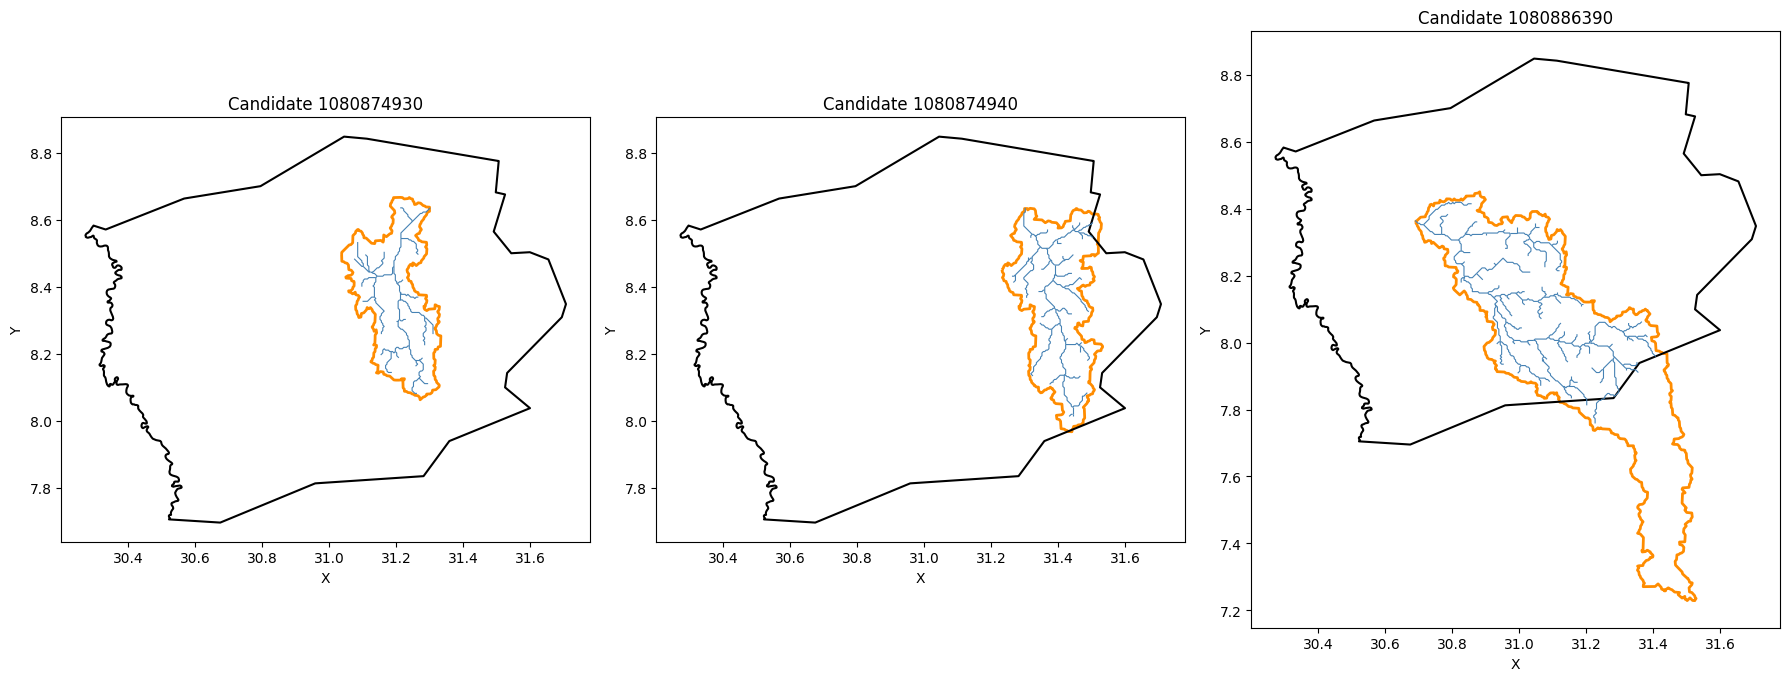

In [83]:
# Step 3c: Map the three Ayod candidates and their intersecting rivers

ayod_candidate_ids = [1080874930, 1080874940, 1080886390]

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, candidate_id in zip(axes, ayod_candidate_ids):
    candidate = ayod_candidates.loc[
        ayod_candidates["HYBAS_ID"] == candidate_id
    ]

    # Rivers intersecting both this candidate and Ayod
    result = next(
        item for item in river_checks
        if item["candidate_id"] == candidate_id
    )

    river_ids = result["river_segments"]["HYRIV_ID"].tolist()

    candidate_geom = candidate.geometry.iloc[0]
    local_river_segments = rivers.loc[
        rivers["HYRIV_ID"].isin(river_ids)
    ]

    # Plot candidate boundary, study-area boundary, and river segments
    gpd.GeoSeries(
        [candidate_geom], crs=rivers.crs
    ).boundary.plot(ax=ax, color="darkorange", linewidth=2)

    ayod_area.boundary.plot(ax=ax, color="black", linewidth=1.5)

    local_river_segments.plot(
        ax=ax, color="steelblue", linewidth=0.8
    )

    ax.set_title(f"Candidate {candidate_id}")
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")

plt.tight_layout()
plt.show()

In [84]:
# Step 3d: Check immediate downstream river links for Ayod

for result in river_checks:
    print(f"\nCandidate {result['candidate_id']}")

    segments = result["river_segments"].copy()
    segment_ids = set(segments["HYRIV_ID"])

    segments["NEXT_DOWN_inside_selected_segments"] = (
        segments["NEXT_DOWN"].isin(segment_ids)
    )

    display(
        segments[
            [
                "HYRIV_ID",
                "NEXT_DOWN",
                "LENGTH_KM",
                "UPLAND_SKM",
                "NEXT_DOWN_inside_selected_segments",
            ]
        ].head(10)
    )


Candidate 1080874940


,HYRIV_ID,NEXT_DOWN,LENGTH_KM,UPLAND_SKM,NEXT_DOWN_inside_selected_segments
693119,10693120,10689582,10.12,1413.8,False
693300,10693301,10693120,1.11,1344.2,True
694753,10694754,10693301,4.46,1313.0,True
694938,10694939,10694754,2.03,1150.4,True
696441,10696442,10694939,4.27,968.5,True
697197,10697198,10696442,2.42,924.5,True
698548,10698549,10697198,3.24,868.7,True
699295,10699296,10698549,2.04,826.8,True
700600,10700601,10699296,4.64,709.4,True
703129,10703130,10700601,7.34,674.4,True



Candidate 1080874930


,HYRIV_ID,NEXT_DOWN,LENGTH_KM,UPLAND_SKM,NEXT_DOWN_inside_selected_segments
691527,10691528,10689582,7.89,1185.5,False
693658,10693659,10691528,7.07,1111.0,True
697383,10697384,10693659,10.21,1006.5,True
699660,10699661,10697384,5.94,594.0,True
700787,10700788,10699661,3.16,553.4,True
701960,10701961,10700788,2.78,510.1,True
704655,10704656,10701961,6.86,374.8,True
698732,10698733,10697384,7.93,351.6,True
704820,10704821,10704656,0.65,325.7,True
708201,10708202,10704821,10.12,313.2,True



Candidate 1080886390


,HYRIV_ID,NEXT_DOWN,LENGTH_KM,UPLAND_SKM,NEXT_DOWN_inside_selected_segments
702355,10702356,10701795,3.33,12150.6,False
703722,10703723,10702356,7.31,12046.5,True
704474,10704475,10703723,6.28,11969.2,True
705917,10705918,10704475,4.08,11487.5,True
707627,10707628,10705918,7.13,11446.3,True
709274,10709275,10707628,4.55,11405.5,True
709466,10709467,10709275,0.46,11199.4,True
711402,10711403,10709467,11.54,11186.9,True
711947,10711948,10711403,2.41,11110.6,True
712902,10712903,10711948,3.26,10770.6,True


In [85]:
# Step 4: Inspect river segments for Bor South candidates

bor_candidate_ids = [1080947990, 1080951620]

bor_area = study_areas.loc[
    study_areas["adm2_name"] == "Bor South"
].to_crs(rivers.crs)

bor_candidates = candidate_geoms.loc[
    (candidate_geoms["area"] == "Bor South")
    & (candidate_geoms["HYBAS_ID"].isin(bor_candidate_ids))
].to_crs(rivers.crs)

bor_river_checks = []

for _, candidate in bor_candidates.iterrows():
    candidate_polygon = candidate.geometry
    area_polygon = bor_area.geometry.iloc[0]

    intersects = rivers[
        rivers.geometry.intersects(candidate_polygon)
        & rivers.geometry.intersects(area_polygon)
    ].copy()

    bor_river_checks.append({
        "candidate_id": int(candidate["HYBAS_ID"]),
        "n_river_segments": len(intersects),
        "river_segments": intersects[
            ["HYRIV_ID", "NEXT_DOWN", "MAIN_RIV",
             "LENGTH_KM", "UPLAND_SKM"]
        ].sort_values("UPLAND_SKM", ascending=False)
    })

for result in bor_river_checks:
    print(
        f"\nCandidate {result['candidate_id']}: "
        f"{result['n_river_segments']} intersecting river segments"
    )
    display(result["river_segments"].head(10))


Candidate 1080951620: 83 intersecting river segments


,HYRIV_ID,NEXT_DOWN,MAIN_RIV,LENGTH_KM,UPLAND_SKM
780111,10780112,10777500,10047863,14.94,2403.4
782705,10782706,10780112,10047863,8.00,2332.2
786441,10786442,10782706,10047863,11.62,2077.2
790786,10790787,10786442,10047863,11.44,2006.8
793182,10793183,10790787,10047863,8.27,1916.0
795107,10795108,10793183,10047863,6.61,1883.1
796083,10796084,10795108,10047863,2.51,1260.8
799919,10799920,10796084,10047863,11.25,1232.2
804748,10804749,10799920,10047863,14.13,1177.4
808357,10808358,10804749,10047863,11.08,1080.9



Candidate 1080947990: 93 intersecting river segments


,HYRIV_ID,NEXT_DOWN,MAIN_RIV,LENGTH_KM,UPLAND_SKM
777694,10777695,10777694,10047863,7.75,1468.1
779255,10779256,10777695,10047863,9.91,1402.2
779902,10779903,10779256,10047863,1.39,1356.8
785472,10785473,10779903,10047863,17.85,1241.3
786644,10786645,10785473,10047863,3.16,1149.4
788090,10788091,10786645,10047863,3.81,1111.8
788675,10788676,10788091,10047863,1.58,1074.3
790340,10790341,10788676,10047863,4.84,1023.1
793577,10793578,10790341,10047863,9.31,977.7
793755,10793756,10793578,10047863,0.46,922.0


In [86]:
# Step 5: Inspect river segments for Malakal candidates

malakal_candidate_ids = [1080826450, 1080826310, 1080820600]

malakal_area = study_areas.loc[
    study_areas["adm2_name"] == "Malakal"
].to_crs(rivers.crs)

malakal_candidates = candidate_geoms.loc[
    (candidate_geoms["area"] == "Malakal")
    & (candidate_geoms["HYBAS_ID"].isin(malakal_candidate_ids))
].to_crs(rivers.crs)

malakal_river_checks = []

for _, candidate in malakal_candidates.iterrows():
    candidate_polygon = candidate.geometry
    area_polygon = malakal_area.geometry.iloc[0]

    intersects = rivers[
        rivers.geometry.intersects(candidate_polygon)
        & rivers.geometry.intersects(area_polygon)
    ].copy()

    malakal_river_checks.append({
        "candidate_id": int(candidate["HYBAS_ID"]),
        "n_river_segments": len(intersects),
        "river_segments": intersects[
            ["HYRIV_ID", "NEXT_DOWN", "MAIN_RIV",
             "LENGTH_KM", "UPLAND_SKM"]
        ].sort_values("UPLAND_SKM", ascending=False)
    })

for result in malakal_river_checks:
    print(
        f"\nCandidate {result['candidate_id']}: "
        f"{result['n_river_segments']} intersecting river segments"
    )
    display(result["river_segments"].head(10))


Candidate 1080826450: 7 intersecting river segments


,HYRIV_ID,NEXT_DOWN,MAIN_RIV,LENGTH_KM,UPLAND_SKM
642211,10642212,10640697,10047863,10.88,348.0
642209,10642210,10642211,10047863,2.04,48.9
641204,10641205,10641371,10047863,7.64,41.0
641532,10641533,10642210,10047863,5.61,30.7
641693,10641694,10640697,10047863,3.39,30.3
640502,10640503,10640504,10047863,5.96,18.6
641533,10641534,10642210,10047863,0.69,11.6



Candidate 1080826310: 1 intersecting river segments


,HYRIV_ID,NEXT_DOWN,MAIN_RIV,LENGTH_KM,UPLAND_SKM
638627,10638628,10638629,10047863,14.11,72.1



Candidate 1080820600: 3 intersecting river segments


,HYRIV_ID,NEXT_DOWN,MAIN_RIV,LENGTH_KM,UPLAND_SKM
635761,10635762,10635763,10047863,8.98,1083.4
638804,10638805,10636271,10047863,14.55,66.0
636435,10636436,10635763,10047863,2.46,25.6


In [87]:
# Step 6: Consolidate the provisional catchment review

review_ids = {
    "Ayod": [1080874930, 1080874940, 1080886390],
    "Bor South": [1080947990, 1080951620],
    "Malakal": [1080826450, 1080826310, 1080820600],
}

review_rows = []

river_check_groups = {
    "Ayod": river_checks,
    "Bor South": bor_river_checks,
    "Malakal": malakal_river_checks,
}

for area, ids in review_ids.items():
    for candidate_id in ids:
        network_row = candidate_network_summary.loc[
            (candidate_network_summary["area"] == area)
            & (candidate_network_summary["candidate_id"] == candidate_id)
        ].iloc[0]

        shortlist_row = candidate_shortlist.loc[
            (candidate_shortlist["area"] == area)
            & (candidate_shortlist["HYBAS_ID"] == candidate_id)
        ].iloc[0]

        river_result = next(
            item for item in river_check_groups[area]
            if item["candidate_id"] == candidate_id
        )

        review_rows.append({
            "area": area,
            "candidate_id": candidate_id,
            "admin_overlap_fraction": shortlist_row["admin_overlap_fraction"],
            "candidate_area_km2": network_row["candidate_sub_area_km2"],
            "upstream_area_km2": network_row["candidate_up_area_km2"],
            "n_upstream_basins": network_row["n_upstream_basins"],
            "river_segments_in_admin_and_candidate": river_result["n_river_segments"],
        })

final_review_table = pd.DataFrame(review_rows)

display(
    final_review_table.sort_values(
        ["area", "candidate_id"]
    ).round(3)
)

,area,candidate_id,admin_overlap_fraction,candidate_area_km2,upstream_area_km2,n_upstream_basins,river_segments_in_admin_and_candidate
0,Ayod,1080874930,0.088,1185.2,1185.5,1,43
1,Ayod,1080874940,0.103,1413.6,1413.8,1,61
2,Ayod,1080886390,0.196,3956.6,12150.6,13,130
3,Bor South,1080947990,0.135,2372.9,2373.5,1,93
4,Bor South,1080951620,0.127,2403.2,2403.4,1,83
7,Malakal,1080820600,0.056,532.6,1177.1,3,3
6,Malakal,1080826310,0.041,208.8,1777.7,5,1
5,Malakal,1080826450,0.188,399.7,399.7,1,7
